# Timestral vs classical benchmarks on retail demand (M5)

**Timestral** is Mistral AI's family of zero-shot foundation models for time series, released on
15 October 2026. This notebook puts it to work on a real demand forecasting problem, the Walmart **M5**
dataset, and compares it with the methods a demand planner would use today, all evaluated with the same
protocol:

| Family | Models | Library |
|---|---|---|
| Baselines | 28-day moving average, Naive, SeasonalNaive (7), Croston SBA | `statsforecast` |
| Time series | AutoARIMA, AutoETS, AutoCES (weekly seasonality) | `statsforecast` |
| Machine learning | global Tweedie LightGBM: plain, level-normalised, level-normalised with direct strategy, level-normalised on Timestral's own inputs | `mlforecast` |
| Foundation model | Timestral 28M: history only, with known covariates, with categorical events, with a past covariate, multivariate | `timestral` |
| Ensembles | equal-weight averages of Timestral, LightGBM and a statistical model | |

**Questions**

1. How is Timestral called, and what exactly does it receive as input?
2. How do you judge a demand forecast? WMAPE alone is misleading on intermittent demand.
3. Does Timestral beat the benchmarks, zero-shot, also when they get the same information? Where does it
   win and where does it lose?
4. Do categorical events, past covariates, multivariate forecasting or ensembles help?
5. Does the ranking survive holiday periods and evaluation at the level of the replenishment decision?
6. Do the quantiles give better stock decisions than a point forecast plus a safety stock?
7. What are the limits and pitfalls of Timestral found along the way?

The notebook runs the whole benchmark itself. The first run downloads M5, computes every model and caches
the forecasts in `data/processed/<department>_<stores>_<tag>/`, one folder per set of origins, the tag a
hash of horizon and origin dates (about two and a half hours on CPU); later runs read them back in
seconds. Deleting a `fc_<model>.parquet` file recomputes only that model.

## 0. Setup

In [1]:
import logging
import os
import time
import warnings

# must be set before numpy and torch are imported
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings(action="ignore")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from timestral.covariate_encoding import target_encode

from timestral_forecast.backtest import (run_benchmark, run_holiday_benchmark,
                                         timestral_variants)
from timestral_forecast.config import Settings
from timestral_forecast.data import download_m5, load_or_build
from timestral_forecast.ensemble import ENSEMBLES, add_ensembles
from timestral_forecast.inventory import (calibration_error, correlation_sweep,
                                          cross_validate_correlation, normal_order_up_to,
                                          quantile_order_up_to, service_metrics)
from timestral_forecast.metrics import (aggregate_periods, bias, bootstrap_difference,
                                        bootstrap_scores, coverage, evaluate, fold_table,
                                        forecast_value_added, score, weighted_quantile_loss, wmape)
from timestral_forecast.models.lgbm import LGBM_VARIANTS
from timestral_forecast.models.timestral_model import load_timestral, prepare_inputs, quantile_column
from timestral_forecast.multivariate import affinity_groups, weekly_profiles
from timestral_forecast.plotting import (FIG_WIDTH, plot_heatmap, plot_sales_overview,
                                         plot_score_bars, plot_segment_examples,
                                         plot_series_forecast, plot_timestral_inputs,
                                         plot_wmape_bias)
from timestral_forecast.preprocessing import (TimestralInputs, backtest_cutoffs,
                                              build_timestral_arrays, mask_constant_covariate,
                                              split_at, store_of, store_totals)
from timestral_forecast.segmentation import adi_cv2_class

logging.basicConfig(level=logging.WARNING)
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

The experiment settings live in `timestral_forecast.config.Settings`; every field can be overridden
with a `TF_*` environment variable or a `.env` file (see `.env.example`). The ones that shape the analysis:

In [3]:
settings = Settings()

settings.model_dump(include={"dept_id", "store_ids", "horizon", "n_windows", "holiday_cutoffs",
                             "timestral_models", "timestral_max_context", "timestral_group_size"})

{'dept_id': 'FOODS_3',
 'store_ids': ('CA_1', 'TX_1', 'WI_1'),
 'horizon': 28,
 'n_windows': 3,
 'holiday_cutoffs': (datetime.date(2015, 6, 21),
  datetime.date(2015, 11, 22),
  datetime.date(2015, 12, 20)),
 'timestral_models': ('mistralai/Timestral-28M',),
 'timestral_max_context': 1024,
 'timestral_group_size': 4}

## 1. Data: an M5 subset

M5 is the dataset of the Walmart forecasting competition: daily unit sales per item and store, with
prices, events and SNAP days (the days food-stamp benefits are paid out). We keep department **FOODS_3**
in three stores of three states (CA_1, TX_1, WI_1). The archive comes from Nixtla's public mirror and is
turned into the long format `unique_id, ds, y` used by the Nixtla suite:

* `y_df`: the target, one row per series and day;
* `x_df`: covariates known in advance (price, SNAP day, event flag, type and name);
* `s_df`: static attributes, one row per series.

In [4]:
zip_path = download_m5(url=settings.m5_url, raw_dir=settings.raw_dir)
data = load_or_build(zip_path, cache_dir=settings.processed_dir, dept_id=settings.dept_id,
                     store_ids=settings.store_ids)
y_df, x_df, s_df = data.y_df, data.x_df, data.s_df

print(f"{y_df.unique_id.nunique():,} series x {y_df.ds.nunique():,} days ({y_df.ds.min().date()} -> {y_df.ds.max().date()}), {len(y_df):,} rows")

2,469 series x 1,941 days (2011-01-29 -> 2016-05-22), 4,792,329 rows


`y_df` holds the target: units sold per series (`unique_id` = item and store) and day. Every series
starts on the first M5 date, so items launched later begin with a run of zeros that are not demand.

In [5]:
y_df.head()

,unique_id,ds,y
0,FOODS_3_001_CA_1,2011-01-29,1.0
1,FOODS_3_002_CA_1,2011-01-29,0.0
2,FOODS_3_003_CA_1,2011-01-29,0.0
3,FOODS_3_004_CA_1,2011-01-29,0.0
4,FOODS_3_005_CA_1,2011-01-29,1.0


`x_df` holds what is known in advance: the weekly `sell_price` (missing until the item goes on sale),
the 0/1 flags `snap` (food-stamp day in the store's state) and `is_event`, and two categorical columns,
`event_type` (sporting, cultural, national, religious) and `event_name` (Christmas, Thanksgiving,
SuperBowl...), both `none` on days without an event.

In [6]:
x_df.head()

,unique_id,ds,sell_price,snap,is_event,event_type,event_name
0,FOODS_3_001_CA_1,2011-01-29,2.28,0.0,0.0,none,none
1,FOODS_3_002_CA_1,2011-01-29,NaN,0.0,0.0,none,none
2,FOODS_3_003_CA_1,2011-01-29,NaN,0.0,0.0,none,none
3,FOODS_3_004_CA_1,2011-01-29,NaN,0.0,0.0,none,none
4,FOODS_3_005_CA_1,2011-01-29,1.98,0.0,0.0,none,none


`s_df` holds the static attributes of each series. LightGBM uses item and store as categorical
features (except the `-matched` variants); for Timestral the store defines the store total and the multivariate groups.

In [7]:
s_df.head()

,unique_id,item_id,dept_id,cat_id,store_id,state_id
0,FOODS_3_001_CA_1,FOODS_3_001,FOODS_3,FOODS,CA_1,CA
1,FOODS_3_002_CA_1,FOODS_3_002,FOODS_3,FOODS,CA_1,CA
2,FOODS_3_003_CA_1,FOODS_3_003,FOODS_3,FOODS,CA_1,CA
3,FOODS_3_004_CA_1,FOODS_3_004,FOODS_3,FOODS,CA_1,CA
4,FOODS_3_005_CA_1,FOODS_3_005,FOODS_3,FOODS,CA_1,CA


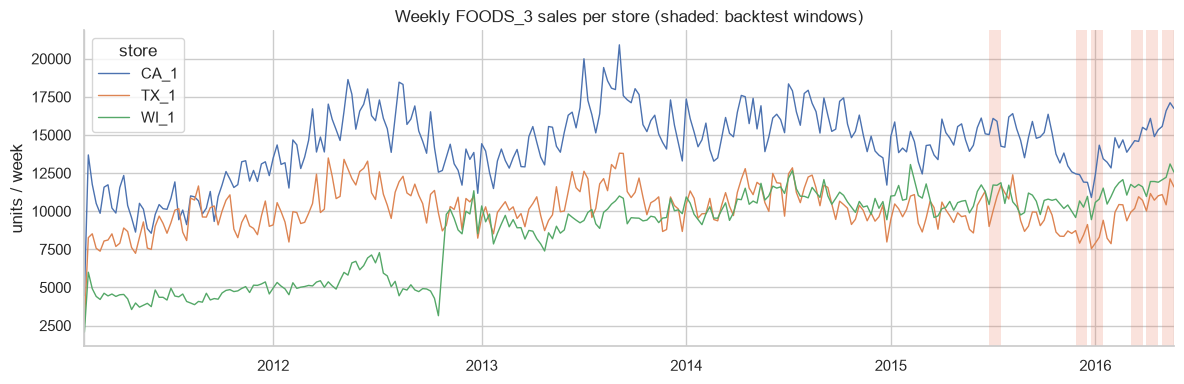

In [8]:
cutoffs = backtest_cutoffs(last_ds=y_df["ds"].max(), horizon=settings.horizon,
                           n_windows=settings.n_windows)
holiday_cutoffs = [pd.Timestamp(cutoff) for cutoff in settings.holiday_cutoffs]
H = pd.Timedelta(days=settings.horizon)
windows = [(cutoff + pd.Timedelta(days=1), cutoff + H) for cutoff in [*holiday_cutoffs, *cutoffs]]

plot_sales_overview(y_df, s_df=s_df, windows=windows)
plt.tight_layout()
plt.show()

Descriptive statistics use only the history up to the first origin, so that no information from
the evaluation windows leaks into the analysis.

In [9]:
history_df = y_df[y_df["ds"] <= cutoffs[0]]
segments_df = adi_cv2_class(y_df=history_df)
started = (history_df["y"] > 0).groupby(by=history_df["unique_id"]).cummax()
first_sale = history_df[history_df["y"] > 0].groupby(by="unique_id")["ds"].min()
vol = segments_df["volume"].sort_values(ascending=False)

print(f"Zero days after launch: {(history_df.loc[started, 'y'] == 0).mean():.0%}")
print(f"Series launched after the first day: {(first_sale > y_df.ds.min()).mean():.0%}")
print(f"Volume share of the top 10% series: {vol.head(n=len(vol) // 10).sum() / vol.sum():.0%}")

Zero days after launch: 47%
Series launched after the first day: 72%
Volume share of the top 10% series: 52%


**Reading.** Sales have a strong weekly pattern, a yearly cycle and a near-zero day every Christmas,
when the stores close. The shaded areas are the evaluation windows: the three main origins at the end
of the data and the three holiday origins used in section 9. Each store has its own level and trend, so
store traffic is information a series-level model cannot see by itself, which motivates the past
covariate tried in section 7.

### Demand segments

The Syntetos-Boylan classification splits series by the average interval between sales (ADI) and the
variability of non-zero sales (CV²). It matters because each segment rewards a different point forecast.

In [10]:
segment_summary_df = segments_df.groupby(by="segment").agg(series=("adi", "size"), volume=("volume", "sum"))
segment_summary_df["% series"] = segment_summary_df["series"] / segment_summary_df["series"].sum()
segment_summary_df["% volume"] = segment_summary_df["volume"] / segment_summary_df["volume"].sum()

(segment_summary_df[["series", "% series", "% volume"]].style.format(formatter={"% series": "{:.0%}", "% volume": "{:.0%}"}))

,series,% series,% volume
segment,,,
erratic,116,5%,14%
intermittent,1434,58%,28%
lumpy,651,26%,24%
smooth,268,11%,34%


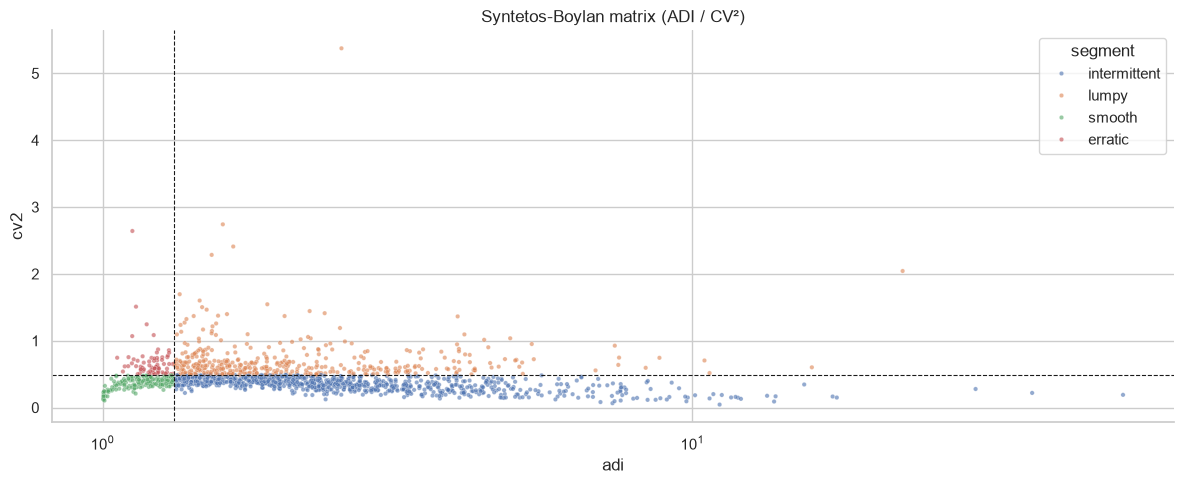

In [11]:
sample_df = segments_df.sample(n=min(1500, len(segments_df)), random_state=0)

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))
sns.scatterplot(data=sample_df, x="adi", y="cv2", hue="segment", s=10, alpha=0.6, ax=ax)
ax.axvline(x=1.32, color="k", lw=0.8, ls="--")
ax.axhline(y=0.49, color="k", lw=0.8, ls="--")
ax.set_xscale("log")
ax.set_title("Syntetos-Boylan matrix (ADI / CV²)")
plt.tight_layout()
plt.show()

One example per segment: the series at the 90th percentile of volume within the segment, so that
the examples are representative of the volume that drives the metrics.

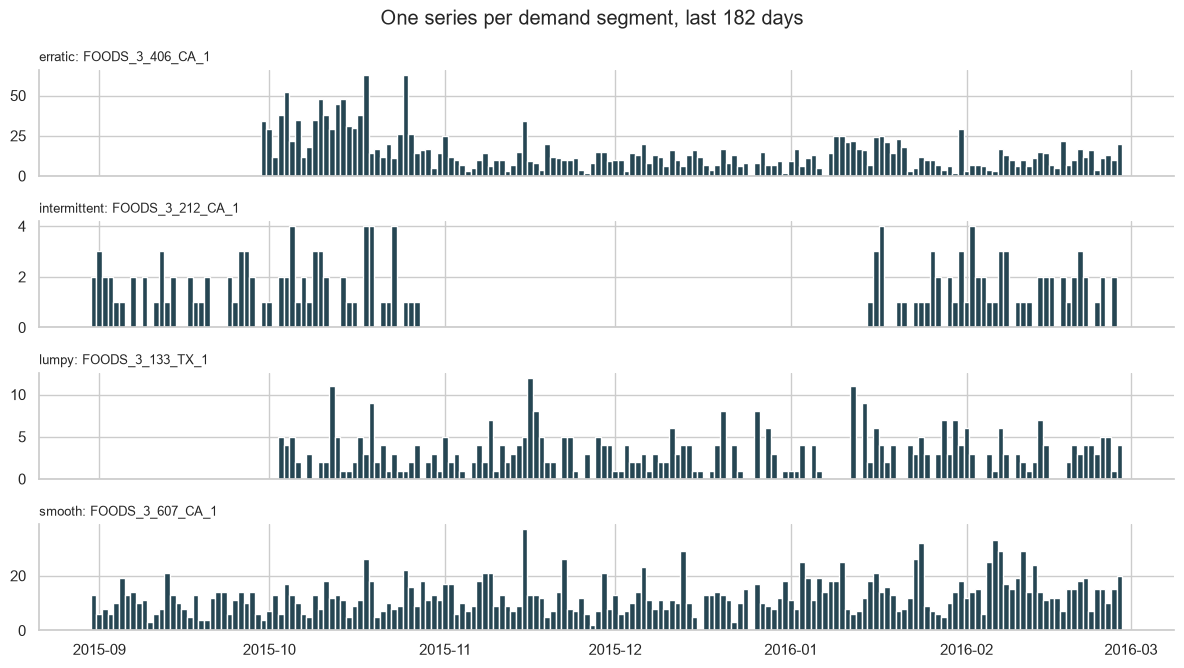

In [12]:
ranked_df = segments_df.sort_values(by="volume")
examples = pd.Series({segment: segment_df.index[int(len(segment_df) * 0.9)]
                      for segment, segment_df in ranked_df.groupby(by="segment")})

plot_segment_examples(y_df=history_df, examples=examples)
plt.tight_layout()
plt.show()

Most series are **intermittent**: many zero days and small quantities, the hardest case for every
model and the one where WMAPE alone misleads (section 4). Volume, however, is concentrated in the
*smooth* and *erratic* series, which therefore weigh most in volume-weighted metrics.

### Prices

Price is the covariate with the most potential, and the most trouble (section 12).

In [13]:
ctx_start = cutoffs[-1] - pd.Timedelta(days=settings.timestral_max_context - 1)
recent_prices_df = x_df[x_df["ds"].between(left=ctx_start, right=cutoffs[-1])]
moves = recent_prices_df.groupby(by="unique_id")["sell_price"].nunique()
horizon_prices_df = x_df[x_df["ds"].between(left=cutoffs[-1] + pd.Timedelta(days=1), right=cutoffs[-1] + H)]
changes_in_horizon = horizon_prices_df.groupby(by="unique_id")["sell_price"].nunique() > 1

print(f"Series whose price never moved in the {settings.timestral_max_context} context days: {(moves <= 1).mean():.0%}")
print(f"Series with a price change inside the last 28-day window: {changes_in_horizon.mean():.0%}")

Series whose price never moved in the 1024 context days: 41%
Series with a price change inside the last 28-day window: 4%


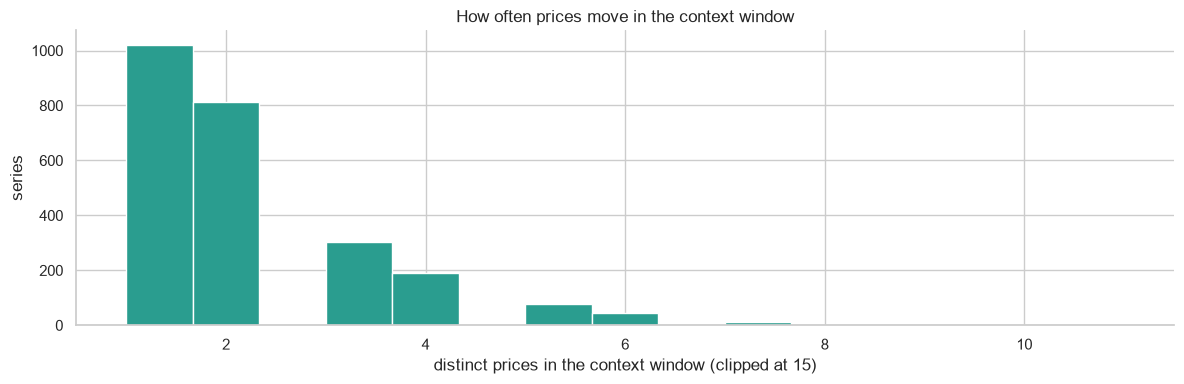

In [14]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4))
moves.clip(upper=15).plot.hist(bins=15, ax=ax, color="#2a9d8f")
ax.set_xlabel("distinct prices in the context window (clipped at 15)")
ax.set_ylabel("series")
ax.set_title("How often prices move in the context window")
plt.tight_layout()
plt.show()

**Reading.** At the last origin 41% of the series have a price that never moved in the 1,024 days
Timestral reads, and only 4% see a price change inside the 28-day window. Price is therefore informative
for a minority of series, and for the flat ones it is worse than useless: section 12 shows how a constant
row interacts with Timestral's per-row normalisation.

## 2. Timestral in a nutshell

The package installs from the official repository and depends only on torch, numpy, safetensors and
huggingface_hub. Weights are downloaded from Hugging Face on first use (111 MB for the 28M). The larger
209M checkpoint is left out of this analysis: with covariates its forecasts stayed unstable even with the
safeguard described in section 12. The whole API is one class and one method:

```python
from timestral import TimestralForecaster

model = TimestralForecaster.from_pretrained("mistralai/Timestral-28M", device="cpu", max_context=1024)
forecast = model.forecast(
    context,                 # (B, V, T) target history, NaN = missing
    prediction_length=28,    # H
    known_covariates=None,   # (B, C, T + H): known over context AND horizon (price, calendar...)
    past_covariates=None,    # (B, P, T): observed over the context only (store traffic...)
    categorical_known_covariates=None,  # (B, K, T + H): category codes (event name...)
)
forecast.quantiles           # torch tensor (B, V, H, 21)
forecast.quantile_levels     # (0.01, 0.05, 0.1, ..., 0.9, 0.95, 0.99)
forecast.median              # (B, V, H)
```

* **B** is the batch of independent series, **V** the target variates forecast *jointly* (attention runs
  across them), **T** the context length, **H** the horizon.
* Two defaults matter: `symmetric_averaging` averages the forecast of the context with the mirrored
  forecast of `-context` (and of negated covariates), and `clip_nonnegative` clips at zero the series whose
  context is never negative.
* `max_context` keeps only the last N steps. 1024 days, almost three years, is enough to see the yearly
  cycle and halves the runtime compared with the full history.

A first call on the best-selling smooth series, passed as a plain `(T,)` array:

In [15]:
model_28m = load_timestral(model_id="mistralai/Timestral-28M", device=settings.device,
                           max_context=settings.timestral_max_context)
unique_id = segments_df[segments_df.segment == "smooth"].sort_values(by="volume").index[-1]
one = y_df[(y_df.unique_id == unique_id) & (y_df.ds <= cutoffs[-1])]["y"].to_numpy()

t0 = time.perf_counter()
fc = model_28m.forecast(context=one, prediction_length=settings.horizon)
elapsed = time.perf_counter() - t0

print(f"{unique_id}: context {one.shape} -> quantiles {tuple(fc.quantiles.shape)} in {elapsed:.2f}s")
print(f"Quantile levels: {fc.quantile_levels}")

FOODS_3_586_TX_1: context (1913,) -> quantiles (1, 1, 28, 21) in 0.03s
Quantile levels: (0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99)


Each row is a forecast day and each column a quantile level (every fourth of the 21). The spread
between q01 and q99 is the model's uncertainty: for this high-volume item it goes from about half to about
1.6 times the median.

In [16]:
forecast_days = pd.date_range(start=cutoffs[-1] + pd.Timedelta(days=1), periods=settings.horizon).date
levels = [f"q{round(level * 100):02d}" for level in fc.quantile_levels]
quantiles_df = pd.DataFrame(data=fc.quantiles[0, 0].numpy(), index=forecast_days, columns=levels)

quantiles_df.iloc[:, ::4].head().style.format(formatter="{:.1f}")

,q01,q20,q40,q60,q80,q99
2016-04-25,25.6,41.0,46.3,50.9,56.8,79.2
2016-04-26,22.4,37.8,43.0,47.4,53.2,74.0
2016-04-27,22.5,38.2,43.2,47.7,53.8,74.8
2016-04-28,22.8,39.1,44.0,48.5,54.6,76.3
2016-04-29,25.1,42.2,47.7,52.7,59.1,83.2


## 3. How the data is passed to Timestral

For the backtest on thousands of series we use the **batched univariate** setup: each series is one batch
element (B) with a single target variate (V = 1). `build_timestral_arrays` turns the long frames into
arrays for one origin, following three rules:

* **Before launch = NaN, not zero.** Before its first sale the item was not on the shelf; zeros would
  teach the model a demand that never existed. After launch a zero is real demand.
* **Known covariates `(B, C, T + H)`** cover the context **and** the horizon: price, SNAP day and event day,
  which are planned in advance, plus sine/cosine of day of week and day of year. Rows that only take
  0/1 values are treated by the model as indicators.
* **Covariates are not forecast**: they condition the target forecast and never read the target.

In [17]:
inputs = build_timestral_arrays(y_df=y_df, cutoff=cutoffs[-1], horizon=settings.horizon, x_df=x_df)
B, V, T = inputs.context.shape

print(f"context: {inputs.context.shape}, float32, NaN share (pre-launch) {np.isnan(inputs.context).mean():.1%}")
print(f"known_covariates: {inputs.known_covariates.shape}, rows {inputs.covariate_names}")
print(f"unique_ids: {inputs.unique_ids.shape}, e.g. {inputs.unique_ids[:3].tolist()}")
print(f"forecast dates: {inputs.future_ds[0].date()} -> {inputs.future_ds[-1].date()} (H = {len(inputs.future_ds)})")

context: (2469, 1, 1913), float32, NaN share (pre-launch) 22.0%
known_covariates: (2469, 7, 1941), rows ('sell_price', 'snap', 'is_event', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos')
unique_ids: (2469,), e.g. ['FOODS_3_001_CA_1', 'FOODS_3_001_TX_1', 'FOODS_3_001_WI_1']
forecast dates: 2016-04-25 -> 2016-05-22 (H = 28)


The same arrays seen as a table for one series around the origin: the last 5 context days and the
first 5 horizon days. The target stops at the origin (it is what the model has to fill in), while the
known covariates carry on into the horizon.

In [18]:
def input_table(inputs: TimestralInputs, unique_id: str, days: int = 5) -> pd.DataFrame:
    i = inputs.index_of(unique_id)
    t = inputs.context.shape[-1]
    dates = inputs.context_ds.append(inputs.future_ds)
    rows = {"target": np.append(arr=inputs.context[i, 0], values=[np.nan] * len(inputs.future_ds))}
    rows |= dict(zip(inputs.covariate_names, inputs.known_covariates[i], strict=True))
    return pd.DataFrame(data=rows, index=dates.date).T.round(decimals=3).iloc[:, t - days : t + days]


input_table(inputs, unique_id)

,2016-04-20,2016-04-21,2016-04-22,2016-04-23,2016-04-24,2016-04-25,2016-04-26,2016-04-27,2016-04-28,2016-04-29
target,45.000,59.000,50.000,56.000,58.000,NaN,NaN,NaN,NaN,NaN
sell_price,1.680,1.680,1.680,1.680,1.680,1.680,1.680,1.680,1.680,1.680
snap,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
is_event,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
dow_sin,0.975,0.434,-0.434,-0.975,-0.782,0.000,0.782,0.975,0.434,-0.434
dow_cos,-0.223,-0.901,-0.901,-0.223,0.623,1.000,0.623,-0.223,-0.901,-0.901
doy_sin,0.943,0.937,0.931,0.925,0.918,0.911,0.904,0.896,0.889,0.881
doy_cos,-0.332,-0.348,-0.364,-0.380,-0.396,-0.412,-0.428,-0.443,-0.458,-0.474


The most recently launched item shows the pre-launch rule at work: everything before its first sale
is passed as missing.

In [19]:
late = first_sale.sort_values().index[-1]
n_missing = np.isnan(inputs.context[inputs.index_of(late), 0]).sum()

print(f"{late} first sold on {first_sale[late].date()}: its first {n_missing} of {T} context steps are NaN (not on the shelf yet)")

FOODS_3_595_CA_1 first sold on 2016-02-17: its first 1845 of 1913 context steps are NaN (not on the shelf yet)


The same arrays as a picture: the last 120 context days of the target and every known covariate row,
with the forecast horizon shaded. Price changes rarely, SNAP and events are sparse 0/1 indicators,
and the calendar rows carry the weekly and yearly cycle into the horizon.

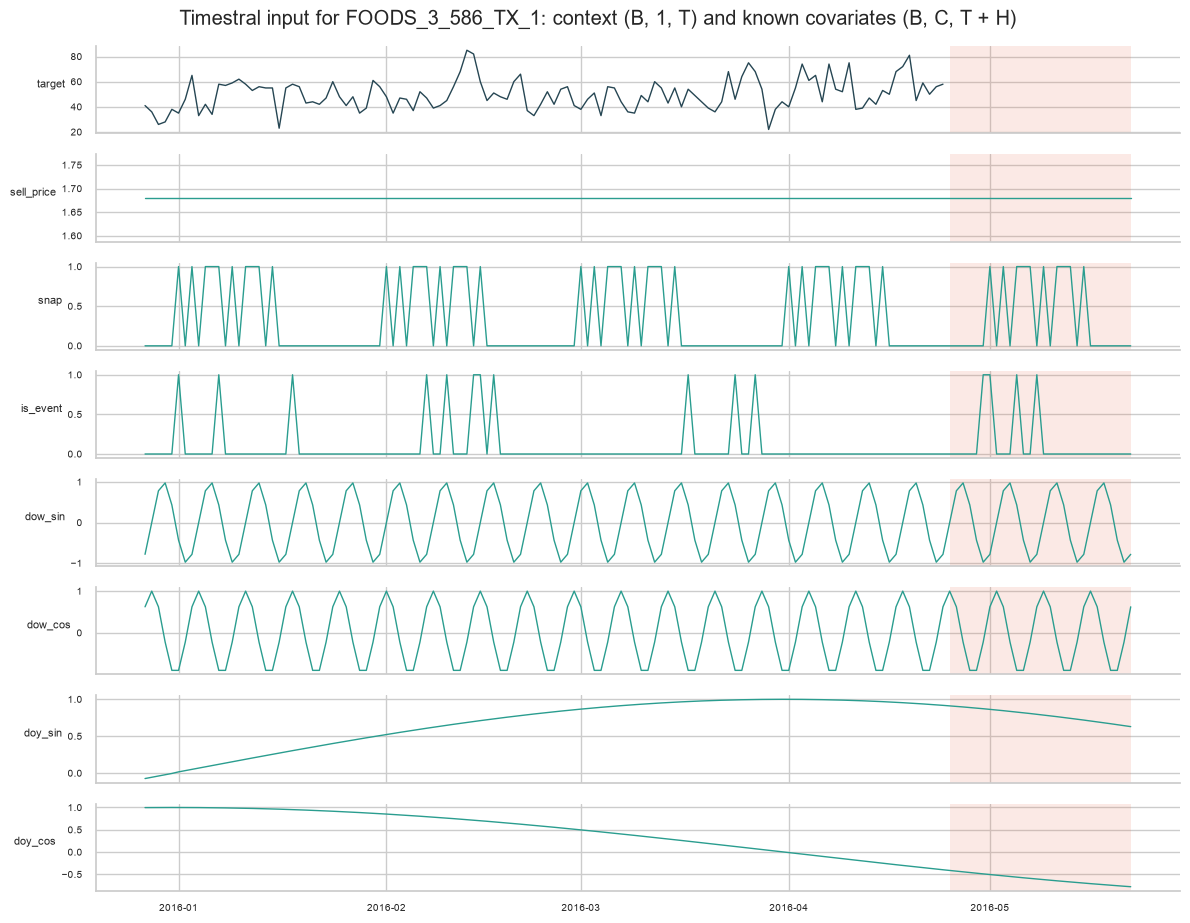

In [20]:
plot_timestral_inputs(inputs, unique_id)
plt.tight_layout()
plt.show()

### The Timestral configurations of the benchmark

Beyond the history-only and known-covariate runs, three extensions use the other input types of the API:

* **`+cat`**: the known covariates with the 0/1 event row replaced by two **categorical covariates**,
  event name and event type `(B, 2, T + H)`, passed as category codes. Timestral target-encodes them per
  series over the context it reads: in series *i*, category *c* becomes
  `(mean_i + sum_ic) / (1 + count_ic)`, the item's mean sales on the past days of that category shrunk
  towards its overall mean. A closure such as Christmas, with no sales in past years, should get a value
  well below that of an ordinary day, instead of the same 1 as any other event.
* **`+past`**: the known covariates plus a **past-only covariate**, the daily department total of the
  series' store `(B, 1, T)`. It carries store traffic, closures and local shocks without leaking the
  future.
* **`-mv` (multivariate)**: items of the same store forecast **jointly** as variates of one batch element,
  `(G, V, T)` with V = 4. Groups are formed by clustering the weekly sales of the last year (average linkage
  on 1 - correlation, consecutive leaves of the dendrogram). Covariates must be shared by the whole group,
  so price is dropped and only store-level rows remain (SNAP, events, calendar, store total).

One row per Timestral configuration, with the inputs it receives: the known and categorical covariates, whether the
store total is added as a past covariate, how many series share a batch element, and the two safeguards.

In [21]:
variants = {variant.alias: variant for variant in timestral_variants(settings)}
variants_df = pd.DataFrame(data=[variant.__dict__ for variant in variants.values()]).set_index(keys="alias")

variants_df

,model_id,known_covariates,past_covariates,categorical_covariates,group_size,symmetric_averaging,mask_constant_price
alias,,,,,,,
Timestral-28M,mistralai/Timestral-28M,(),False,(),1,True,False
Timestral-28M+cov,mistralai/Timestral-28M,"(sell_price, snap, is_event)",False,(),1,True,True
Timestral-28M+cov+past,mistralai/Timestral-28M,"(sell_price, snap, is_event)",True,(),1,True,True
Timestral-28M-mv,mistralai/Timestral-28M,"(snap, is_event)",True,(),4,True,False
Timestral-28M+cov+cat,mistralai/Timestral-28M,"(sell_price, snap)",False,"(event_name, event_type)",1,True,True


The shapes actually passed to the model at the last origin. The categorical run adds an array of
event codes; the multivariate run needs two calls,
because groups of 4 do not divide every store exactly: the remainder forms smaller groups.

In [22]:
past_df = store_totals(y_df, s_df)
stores = store_of(s_df)
arrays = ("context", "known_covariates", "categorical_covariates", "past_covariates")

for alias in ("Timestral-28M+cov+cat", "Timestral-28M+cov+past", "Timestral-28M-mv"):
    parts = prepare_inputs(variant=variants[alias], y_df=y_df, cutoff=cutoffs[-1], horizon=settings.horizon,
                           x_df=x_df, past_df=past_df, store_of=stores,
                           context_window=settings.timestral_max_context)
    for part in parts:
        shapes = [f"{name} {getattr(part, name).shape}" for name in arrays if getattr(part, name) is not None]
        print(f"{alias}: {', '.join(shapes)}")

Timestral-28M+cov+cat: context (2469, 1, 1913), known_covariates (2469, 6, 1941), categorical_covariates (2469, 2, 1941)


Timestral-28M+cov+past: context (2469, 1, 1913), known_covariates (2469, 7, 1941), past_covariates (2469, 1, 1913)


Timestral-28M-mv: context (615, 4, 1913), known_covariates (615, 6, 1941), past_covariates (615, 1, 1913)
Timestral-28M-mv: context (3, 3, 1913), known_covariates (3, 6, 1941), past_covariates (3, 1, 1913)


The multivariate group of the example item, plotted with the same weekly profiles the clustering
compares: these items are grouped because their weekly sales are among the most correlated in the store.

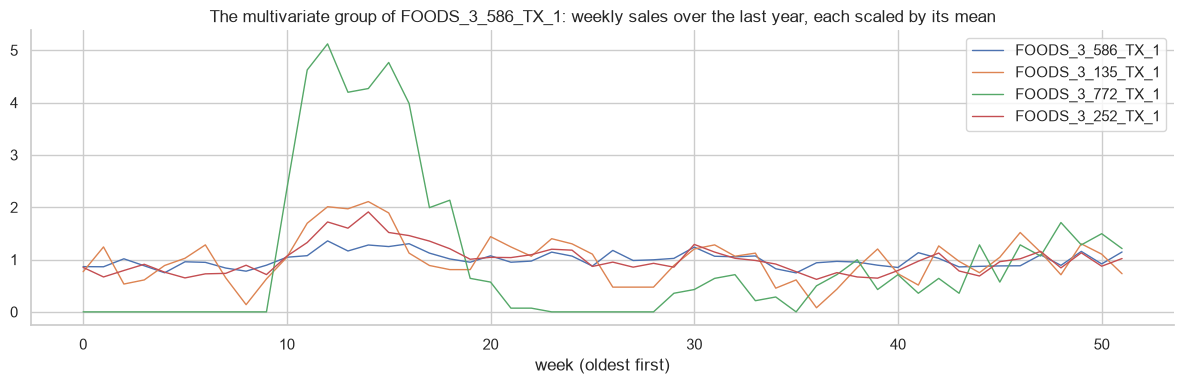

In [23]:
groups = affinity_groups(inputs=inputs, store_of=stores, size=settings.timestral_group_size)
group = next(candidate for candidate in groups if unique_id in inputs.unique_ids[candidate])
weekly_df = pd.DataFrame(data=weekly_profiles(context=inputs.context[group]).T, columns=inputs.unique_ids[group])

ax = (weekly_df / weekly_df.mean()).plot(figsize=(FIG_WIDTH, 4), lw=1)
ax.set_xlabel("week (oldest first)")
ax.set_title(f"The multivariate group of {unique_id}: weekly sales over the last year, each scaled by its mean")
plt.tight_layout()
plt.show()

How Timestral turns the event codes into numbers, for the example item at the Christmas origin
(2015-12-20). For each event in the forecast window: how many times it occurred in the 1,024 context days,
the item's mean sales on those days, and the value the model receives for it (`none`, every day without
an event, is the reference).

In [24]:
xmas_cutoff = pd.Timestamp(settings.holiday_cutoffs[-1])
cat_inp = prepare_inputs(variant=variants["Timestral-28M+cov+cat"], y_df=y_df, cutoff=xmas_cutoff,
                         horizon=settings.horizon, x_df=x_df,
                         context_window=settings.timestral_max_context)[0]
i, T, W = cat_inp.index_of(unique_id), cat_inp.context.shape[-1], settings.timestral_max_context
codes = cat_inp.categorical_covariates[i, cat_inp.categorical_names.index("event_name")]
_, future_encoded = target_encode(target_context=cat_inp.context[i, 0, T - W :],
                                  past_codes=codes[T - W : T], future_codes=codes[T:])

event_names = x_df["event_name"].cat.categories
context_events_df = pd.DataFrame(data={"event_name": event_names[codes[T - W : T].astype(int)],
                                       "y": cat_inp.context[i, 0, T - W :]})
horizon_events_df = pd.DataFrame(data={"event_name": event_names[codes[T:].astype(int)],
                                       "encoded value": future_encoded})
event_encoding_df = (context_events_df.groupby(by="event_name")["y"].agg(func=["size", "mean"])
                     .rename(columns={"size": "context days", "mean": "mean sales"})
                     .join(other=horizon_events_df.groupby(by="event_name")["encoded value"].first(), how="inner"))

event_encoding_df.style.format(formatter={"mean sales": "{:.1f}", "encoded value": "{:.1f}"})

,context days,mean sales,encoded value
event_name,,,
Christmas,2,0.0,17.4
NewYear,2,31.5,38.4
OrthodoxChristmas,2,44.0,46.7
none,947,52.2,52.2


## 4. Protocol and metrics

* **3 consecutive origins**, each followed by 28 days to forecast (the last 12 weeks of M5). Every model
  uses the same origins and sees only data up to the origin.
* **All series** are evaluated; when a model produces no forecast (a series never sold before the
  origin) the forecast is 0, as it would be in production. Negative forecasts are clipped at 0.
* Metrics are computed on the aggregated portfolio:

$$\text{WMAPE} = \frac{\sum |F - A|}{\sum A} \qquad \text{Bias} = \frac{\sum (F - A)}{\sum A} \qquad \text{Score} = \text{WMAPE} + |\text{Bias}|$$

The ranking criterion is the **mean score over the origins**: stricter than the overall score, where
biases of opposite sign in different origins cancel out. **FVA** (Forecast Value Added) is the relative
score reduction versus the 28-day moving average.

WMAPE alone **rewards under-forecasting** on intermittent series, because the forecast that minimises it
is the median. A series with two orders in eight days shows why:

In [25]:
act = np.array([0, 0, 10, 0, 0, 0, 12, 0.0])
candidates = {"always zero (= median)": np.zeros(8), "mean": np.full(shape=8, fill_value=act.mean())}

for name, forecast in candidates.items():
    print(f"{name}: WMAPE {wmape(y=act, y_hat=forecast):.0%}, bias {bias(y=act, y_hat=forecast):+.0%}, score {score(y=act, y_hat=forecast):.0%}")

always zero (= median): WMAPE 100%, bias -100%, score 200%
mean: WMAPE 150%, bias +0%, score 150%


Timestral is probabilistic, so it gets two point forecasts: the **median** (q50) and the **mean**,
approximated as the average of the 21 quantiles (columns ending in `-mean`). We also report the **WQL**,
the scaled pinball loss used in GIFT-Eval, and the **coverage** of the q10–q90 interval, nominally 80%.

## 5. Backtest of every model

In [26]:
t0 = time.perf_counter()
merged_df, timings = run_benchmark(settings, data)
merged_df = add_ensembles(df=merged_df)

print(f"{len(merged_df):,} rows in {time.perf_counter() - t0:.0f}s (from cache when already computed)")

207,396 rows in 2s (from cache when already computed)


`merged_df` has one row per series, forecast day and origin: the actual `y` next to the forecast of every
model (three shown here). Timestral contributes several columns per run: the median, the `-mean` and the
21 quantiles.

In [27]:
TS = [variant.alias for variant in timestral_variants(settings)]
BASE = [f"MA{settings.moving_average_window}", "Naive", "SeasonalNaive", "CrostonSBA"]
STAT = ["AutoARIMA", "AutoETS", "AutoCES"]
LGBM = [variant.alias for variant in LGBM_VARIANTS]
ENS = list(ENSEMBLES)
MODELS = BASE + STAT + LGBM + TS + [f"{a}-mean" for a in TS] + ENS

merged_df[["unique_id", "ds", "cutoff", "y", "Timestral-28M+cov-mean", "LightGBM-norm", "AutoARIMA"]].head()

,unique_id,ds,cutoff,y,Timestral-28M+cov-mean,LightGBM-norm,AutoARIMA
0,FOODS_3_001_CA_1,2016-02-29,2016-02-28,0.0,0.618305,0.537050,0.695620
1,FOODS_3_002_CA_1,2016-02-29,2016-02-28,6.0,3.240729,2.698693,3.382762
2,FOODS_3_003_CA_1,2016-02-29,2016-02-28,0.0,0.001462,0.002383,0.000000
3,FOODS_3_004_CA_1,2016-02-29,2016-02-28,0.0,0.972148,0.899910,1.001668
4,FOODS_3_005_CA_1,2016-02-29,2016-02-28,0.0,0.586599,0.488639,0.532366


## 6. Results

In [28]:
scores_df = fold_table(df=merged_df, models=MODELS, metric="score")
fva = forecast_value_added(table=scores_df, reference=f"MA{settings.moving_average_window}")
overall_df = evaluate(df=merged_df, models=MODELS).set_index(keys="model")
results_df = pd.concat(objs=[overall_df[["wmape", "bias"]].add_suffix(suffix=" (overall)"),
                             scores_df.rename(columns={"mean": "mean score per origin"}), fva], axis=1)
results_df = results_df.sort_values(by="mean score per origin")

(results_df.style.format(formatter="{:.1%}").format(formatter="{:+.1%}", subset=["bias (overall)"])
 .background_gradient(cmap="RdYlGn_r", subset=["mean score per origin"]))

,wmape (overall),bias (overall),2016-02-28,2016-03-27,2016-04-24,mean score per origin,FVA vs MA28
model,,,,,,,
"Ens(TS+cov, LGBM-norm, ETS)",62.4%,+0.7%,64.9%,66.8%,62.0%,64.6%,5.8%
"Ens(TS+cov, LGBM-norm, ARIMA)",62.8%,+0.6%,65.6%,66.7%,62.5%,64.9%,5.4%
"Ens(TS+cov, LGBM-norm)",62.9%,+1.6%,66.7%,67.1%,61.4%,65.1%,5.1%
Timestral-28M+cov-mean,63.5%,+1.2%,66.6%,67.3%,61.6%,65.2%,4.9%
Timestral-28M+cov+past-mean,63.5%,+1.6%,66.9%,67.6%,61.1%,65.2%,4.9%
Timestral-28M-mv-mean,63.5%,+1.8%,66.9%,67.9%,61.3%,65.4%,4.7%
Timestral-28M+cov+cat-mean,63.9%,+1.7%,68.9%,65.2%,62.9%,65.7%,4.2%
LightGBM-norm,63.7%,+2.0%,68.2%,68.3%,62.5%,66.3%,3.3%
Timestral-28M-mean,63.6%,+2.8%,68.0%,70.6%,60.9%,66.5%,3.0%


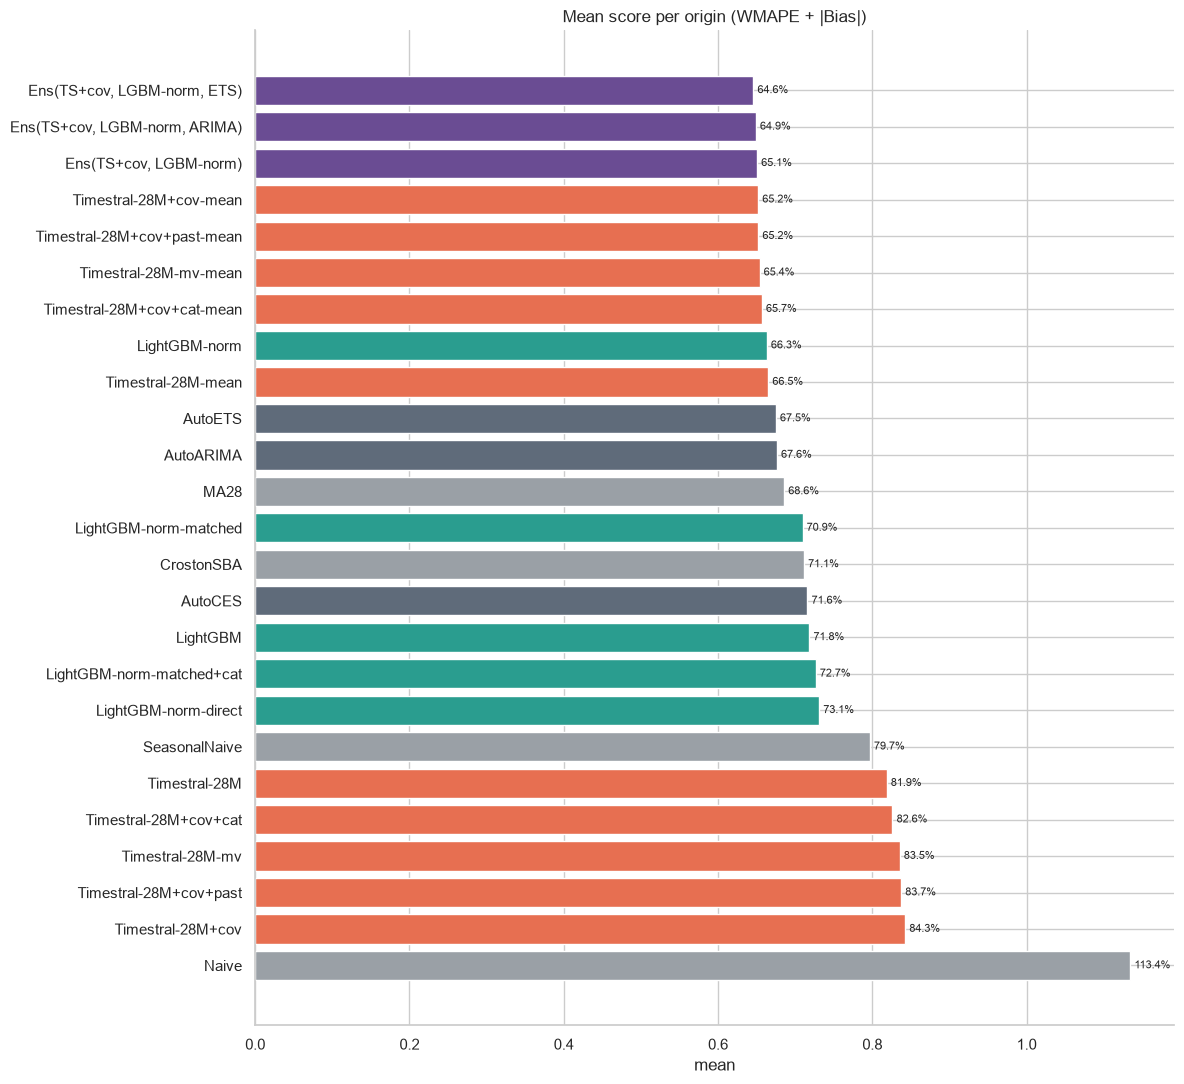

In [29]:
plot_score_bars(summary=scores_df[["mean"]], title="Mean score per origin (WMAPE + |Bias|)", metric="mean")
plt.tight_layout()
plt.show()

The same models on the WMAPE / bias plane (ensembles left out): the Timestral medians sit at low WMAPE
and large negative bias, the means close to zero bias.

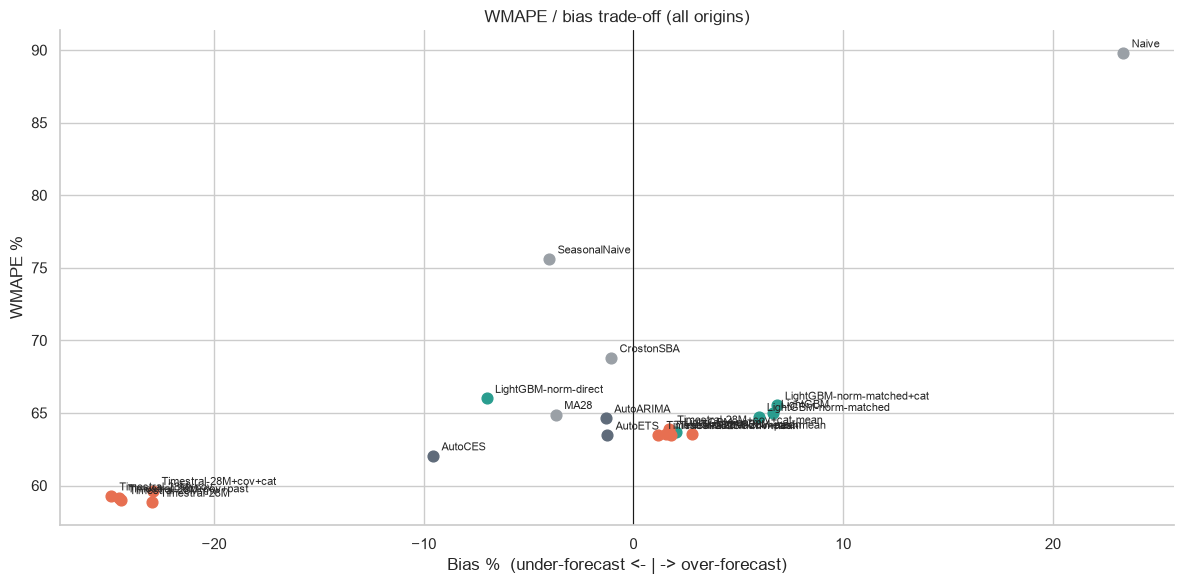

In [30]:
plot_wmape_bias(summary=overall_df.drop(index=ENS))
plt.tight_layout()
plt.show()

**Reading.**

* **The point forecast matters more than the model.** Every Timestral median (rows without `-mean`) has
  the lowest WMAPE of the table (58.8–59.3%) and the worst bias (−23% to −25%): the median of an
  intermittent series is often zero. The mean of the 21 quantiles removes the bias and moves Timestral
  from the bottom to the top. AutoCES shows the same trap from the statistical side: lowest WMAPE among
  the benchmarks, −9.5% bias.
* **Zero-shot Timestral beats every benchmark.** Timestral-28M+cov (mean) scores 65.2% against 66.3% for
  the best LightGBM and 67.5–67.6% for AutoETS and AutoARIMA, an FVA of +4.9% over the moving average.
  The history-only 28M is already level with LightGBM-norm (66.5%).
* **The lead is consistent but not large.** Timestral-28M+cov is ahead of LightGBM-norm on all three
  origins, by 0.9–1.6 points; the spread between origins (61–67%) is larger than the gap between the best
  models.

### How solid is the ranking?

The scores above come from one portfolio of 2,469 items. A **series-level bootstrap** asks how much they
would change with a different draw of items: each of 1,000 resamples draws the series with replacement,
keeps all their days and origins, and recomputes the mean score per origin of every model. The
comparison is **paired** (every model is scored on the same resample), so the difference between two
models is much more precise than either score. The table compares the key models with
Timestral-28M+cov (mean): median difference in score points (negative = better than Timestral), 95%
interval, and share of resamples in which the model wins.

In [31]:
KEY_MODELS = ["Timestral-28M+cov-mean", "Ens(TS+cov, LGBM-norm, ETS)", "Timestral-28M+cov+cat-mean",
              "Timestral-28M-mean", "LightGBM-norm", "LightGBM-norm-matched", "LightGBM-norm-matched+cat",
              "AutoETS", "AutoARIMA", f"MA{settings.moving_average_window}"]
REFERENCE = "Timestral-28M+cov-mean"


def bootstrap_table(df: pd.DataFrame, models: list[str] = KEY_MODELS) -> pd.io.formats.style.Styler:
    boot = bootstrap_scores(df=df, models=models, n_boot=1000, seed=0)
    table = bootstrap_difference(boot=boot, reference=REFERENCE)
    return (table.style.format(formatter="{:+.1%}", subset=["difference", "lower", "upper"])
            .format(formatter="{:.0%}", subset=["share better"]))


bootstrap_table(df=merged_df)

,difference,lower,upper,share better
"Ens(TS+cov, LGBM-norm, ETS)",-0.7%,-1.7%,-0.0%,98%
Timestral-28M+cov+cat-mean,+0.3%,-0.9%,+1.1%,32%
LightGBM-norm,+1.0%,-0.2%,+2.0%,6%
Timestral-28M-mean,+1.3%,+0.3%,+1.9%,0%
AutoETS,+2.1%,-0.2%,+3.8%,4%
AutoARIMA,+2.2%,+0.6%,+3.5%,0%
MA28,+3.1%,+1.2%,+4.8%,0%
LightGBM-norm-matched,+5.4%,+2.8%,+10.1%,0%
LightGBM-norm-matched+cat,+7.1%,+2.9%,+15.2%,0%


**Reading.**

* **Covariates and the ensemble are real gains.** Timestral-28M+cov beats the history-only 28M by 1.3
  points (interval 0.3–2.0) and the moving average by 3.1 (1.2–4.8). The ensemble with AutoETS is ahead
  of Timestral alone in 98% of the resamples, but by only 0.7 points.
* **The lead over the best benchmarks is likely, not certain.** Against LightGBM-norm the difference is
  1.0 point (−0.2 to +2.0), with LightGBM ahead in 6% of the resamples; against AutoETS 2.1 points
  (−0.2 to +3.8). AutoARIMA is behind in every interval (+0.6 to +3.5).
* **Categorical events cannot be told apart** from the 0/1 row on these origins (+0.3, −0.9 to +1.1).
* The bootstrap covers the choice of items, not of origins: with three origins the origin-to-origin
  variation (61–67%) is not in these intervals.

### LightGBM with the same information as Timestral

The LightGBM variants above see more than Timestral: item and store ids, day of month, month and year
(which together single out each holiday), the price relative to its recent level, and the whole history.
The two **`-matched`** variants get exactly Timestral's inputs: raw price, SNAP, events (the 0/1 row, or
event name and type for `+cat`), sine/cosine of day of week and day of year, and the last 1,024 days.
They stay global models trained on all series, which is how LightGBM is used.

In [32]:
matched = ["Timestral-28M+cov-mean", "Timestral-28M+cov+cat-mean", "LightGBM-norm",
           "LightGBM-norm-matched", "LightGBM-norm-matched+cat"]
matched_df = results_df.loc[matched].drop(columns=f"FVA vs MA{settings.moving_average_window}")

matched_df.style.format(formatter="{:.1%}").format(formatter="{:+.1%}", subset=["bias (overall)"])

,wmape (overall),bias (overall),2016-02-28,2016-03-27,2016-04-24,mean score per origin
model,,,,,,
Timestral-28M+cov-mean,63.5%,+1.2%,66.6%,67.3%,61.6%,65.2%
Timestral-28M+cov+cat-mean,63.9%,+1.7%,68.9%,65.2%,62.9%,65.7%
LightGBM-norm,63.7%,+2.0%,68.2%,68.3%,62.5%,66.3%
LightGBM-norm-matched,64.8%,+6.0%,75.5%,75.4%,62.0%,70.9%
LightGBM-norm-matched+cat,65.5%,+6.8%,80.8%,75.0%,62.2%,72.7%


**Reading.**

* **On equal information Timestral wins by five points.** LightGBM-norm-matched scores 70.9% against
  65.2% for Timestral-28M+cov and 66.3% for LightGBM-norm, below the moving average (68.6%); the bootstrap
  difference with Timestral is 5.4 points (2.8–10.1) and LightGBM never wins. With event name and type
  (`+cat`) it is worse still, 72.7%.
* **The loss is in bias and in the first two origins** (75% against 68% for LightGBM-norm): without the
  extra features the trees over-forecast by 6%.
* The gap between LightGBM-norm and its matched version (4.6 points) measures what ids, day / month /
  year, the price ratio and the full history are worth to a tree model. Timestral cannot use them, so the
  main ranking compares each model at its best, and this one compares the methods on the same data.

### Probabilistic quality of Timestral

In [33]:
y = merged_df["y"].to_numpy()
rows = []
for alias in TS:
    qcols = [column for column in merged_df.columns if column.startswith(f"{alias}_q")]
    levels = [int(column[-2:]) / 100 for column in qcols]
    rows.append({"model": alias,
                 "WQL": weighted_quantile_loss(y=y, quantiles=merged_df[qcols].to_numpy(), levels=levels),
                 "q10-q90 coverage": coverage(y=y, lower=merged_df[quantile_column(alias, level=0.1)],
                                              upper=merged_df[quantile_column(alias, level=0.9)]),
                 "median bias": bias(y=y, y_hat=merged_df[alias].to_numpy()),
                 "mean bias": bias(y=y, y_hat=merged_df[f"{alias}-mean"].to_numpy()),
                 "max mean forecast": merged_df[f"{alias}-mean"].max()})

proba_df = pd.DataFrame(data=rows).set_index(keys="model")

(proba_df.style.format(formatter="{:.3f}", subset=["WQL"])
 .format(formatter="{:.0%}", subset=["q10-q90 coverage"])
 .format(formatter="{:+.1%}", subset=["median bias", "mean bias"])
 .format(formatter="{:.0f}", subset=["max mean forecast"]))

,WQL,q10-q90 coverage,median bias,mean bias,max mean forecast
model,,,,,
Timestral-28M,0.408,85%,-23.0%,+2.8%,84
Timestral-28M+cov,0.410,83%,-24.9%,+1.2%,83
Timestral-28M+cov+past,0.409,83%,-24.5%,+1.6%,87
Timestral-28M-mv,0.408,84%,-24.4%,+1.8%,82
Timestral-28M+cov+cat,0.412,84%,-22.9%,+1.7%,89


**Reading.** The distribution is well calibrated: 83–85% of the actuals fall in the nominal 80%
q10–q90 interval (slightly wide), and the WQL is the same for every variant (0.408–0.410), so covariates,
the past covariate and the multivariate grouping do not change the quality of the distribution, only the
level of the centre. The gap between median bias (about −24%) and mean bias (+1% to +3%) quantifies how
skewed the predictive distributions are on this data. With the constant-price mask the largest mean
forecast stays below 90 units for every variant: no more blow-ups.

### By demand segment

Segments are computed from data available at the first origin only.

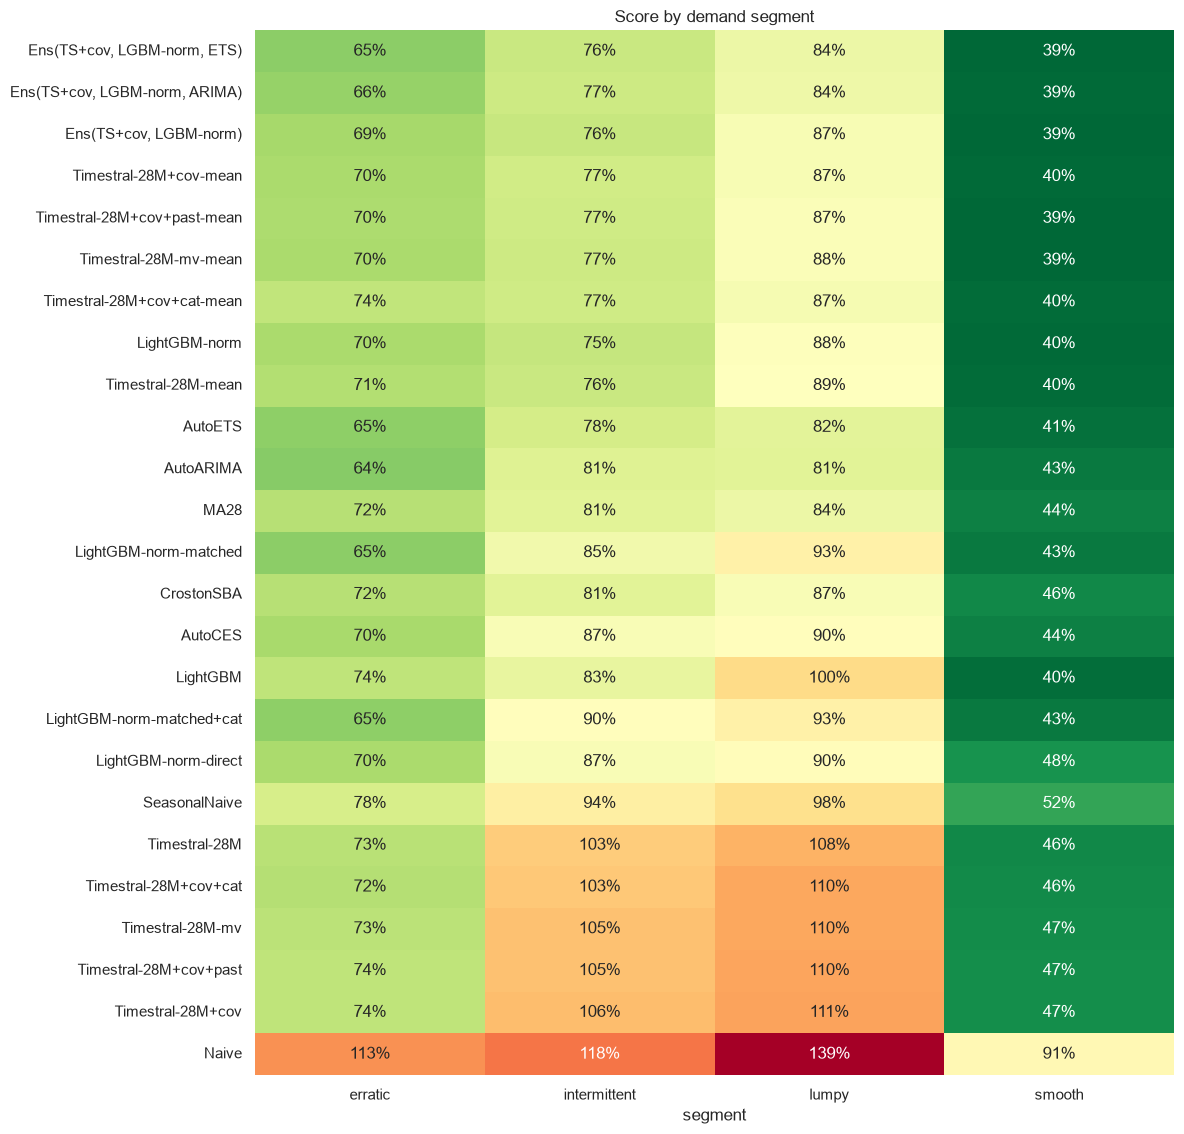

In [34]:
merged_df["segment"] = merged_df["unique_id"].map(segments_df["segment"]).fillna(value="no sales")
segment_scores_df = (evaluate(df=merged_df, models=MODELS, by="segment")
                     .pivot(index="model", columns="segment", values="score"))

plot_heatmap(table=segment_scores_df.loc[results_df.index], xlabel="segment", title="Score by demand segment")
plt.tight_layout()
plt.show()

Share of the evaluated volume in each segment, to weigh the heatmap: smooth and intermittent series
carry two thirds of the units.

In [35]:
volume_share = merged_df.groupby(by="segment")["y"].sum() / merged_df["y"].sum()
volume_share.to_frame(name="volume share").T.style.format(formatter="{:.0%}")

segment,erratic,intermittent,lumpy,smooth
volume share,10%,34%,23%,33%


**Reading.**

* **Smooth** (33% of the evaluated volume) and **intermittent** (34%): Timestral (mean) and LightGBM-norm lead,
  with scores around 0.39–0.40 and 0.75–0.77, against 0.41–0.43 and 0.78–0.81 for ETS and ARIMA.
* **Erratic** and **lumpy**: the statistical models win (AutoARIMA 0.64 on erratic, AutoETS / AutoARIMA
  0.82 on lumpy, against about 0.70 and 0.87 for Timestral). On series with rare, large spikes the
  conservative level of an exponential smoothing pays off.
* The medians collapse on intermittent and lumpy series (scores above 1.0) and are competitive only on
  smooth ones, which confirms that the bias comes from zero-inflated distributions.

Different winners on different segments are the premise of the ensembles in section 8.

### Compute time (CPU, 3 origins, all series)

In [36]:
timings.to_frame(name="seconds").sort_values(by="seconds").style.format(formatter="{:.0f}")

,seconds
baselines,16
Timestral-28M,35
LightGBM-norm-matched+cat,40
LightGBM-norm-matched,42
LightGBM,75
LightGBM-norm,76
ets,81
Timestral-28M-mv,307
Timestral-28M+cov,722
LightGBM-norm-direct,898


### Example forecasts

The 90th-percentile series by volume of each segment, last origin.

In [37]:
last_origin_df = merged_df[merged_df["cutoff"] == cutoffs[-1]]
history_last_df, _ = split_at(df=y_df, cutoff=cutoffs[-1], horizon=settings.horizon)
best_ts = "Timestral-28M+cov"


def plot_example(segment: str) -> None:
    example = examples[segment]
    example_df = last_origin_df[last_origin_df.unique_id == example].sort_values(by="ds")
    ax = plot_series_forecast(history=history_last_df, window=last_origin_df, alias=best_ts,
                              unique_id=example)
    ax.plot(example_df["ds"], example_df["LightGBM-norm"], color="#2a9d8f", lw=1.2,
            label="LightGBM-norm")
    ax.plot(example_df["ds"], example_df["AutoARIMA"], color="#5f6b7a", lw=1.2, ls="--",
            label="AutoARIMA")
    ax.legend(loc="upper left", fontsize=8, ncol=8)
    ax.set_title(f"{example} ({segment}) - {best_ts}")
    plt.tight_layout()
    plt.show()

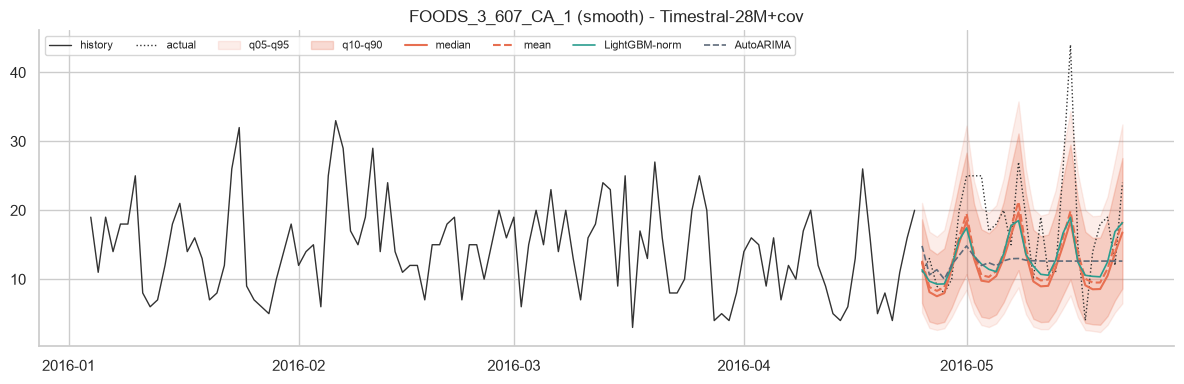

In [38]:
plot_example(segment="smooth")

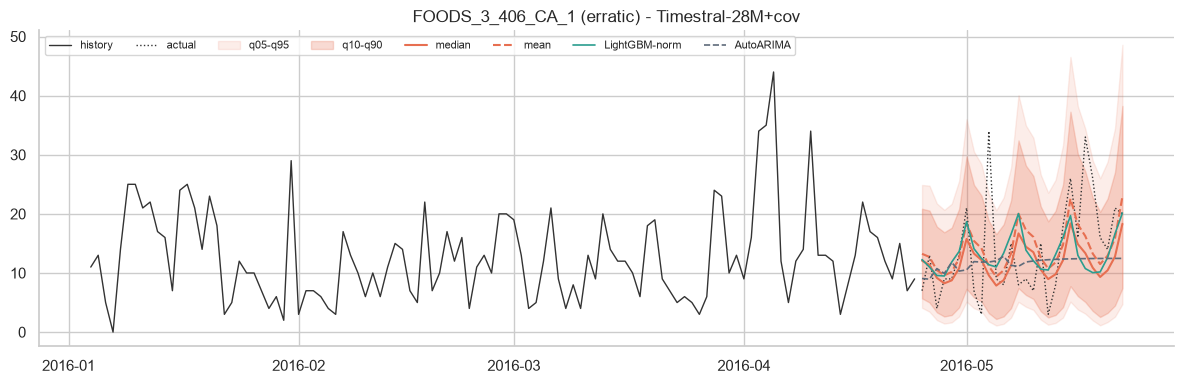

In [39]:
plot_example(segment="erratic")

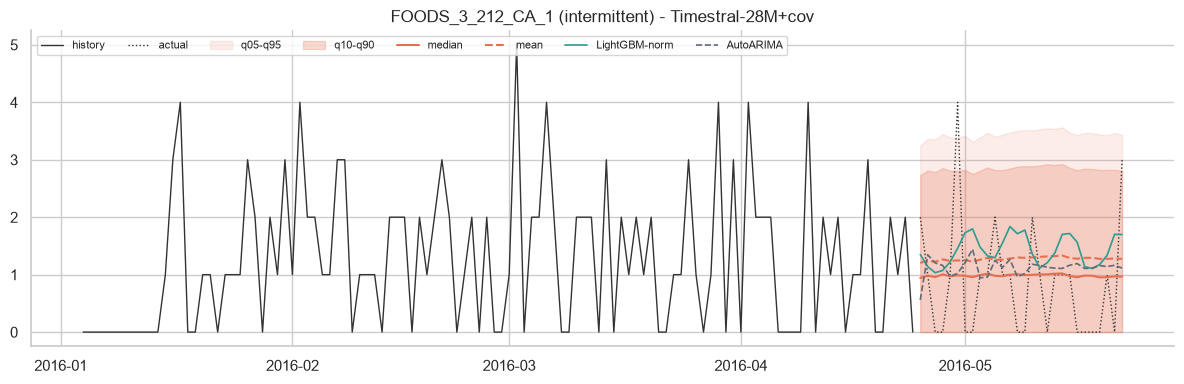

In [40]:
plot_example(segment="intermittent")

## 7. Timestral extensions: categorical events, past covariate and multivariate

In [41]:
ext = ["Timestral-28M-mean", "Timestral-28M+cov-mean", "Timestral-28M+cov+cat-mean",
       "Timestral-28M+cov+past-mean", "Timestral-28M-mv-mean", "LightGBM-norm"]
extensions_df = results_df.loc[ext, ["wmape (overall)", "bias (overall)", "mean score per origin"]]
extensions_df["seconds"] = [timings.get(alias.removesuffix("-mean")) for alias in ext]

(extensions_df.style.format(formatter="{:.1%}", subset=["wmape (overall)", "mean score per origin"])
 .format(formatter="{:+.1%}", subset=["bias (overall)"])
 .format(formatter="{:.0f}", subset=["seconds"]))

,wmape (overall),bias (overall),mean score per origin,seconds
model,,,,
Timestral-28M-mean,63.6%,+2.8%,66.5%,35
Timestral-28M+cov-mean,63.5%,+1.2%,65.2%,722
Timestral-28M+cov+cat-mean,63.9%,+1.7%,65.7%,898
Timestral-28M+cov+past-mean,63.5%,+1.6%,65.2%,902
Timestral-28M-mv-mean,63.5%,+1.8%,65.4%,307
LightGBM-norm,63.7%,+2.0%,66.3%,76


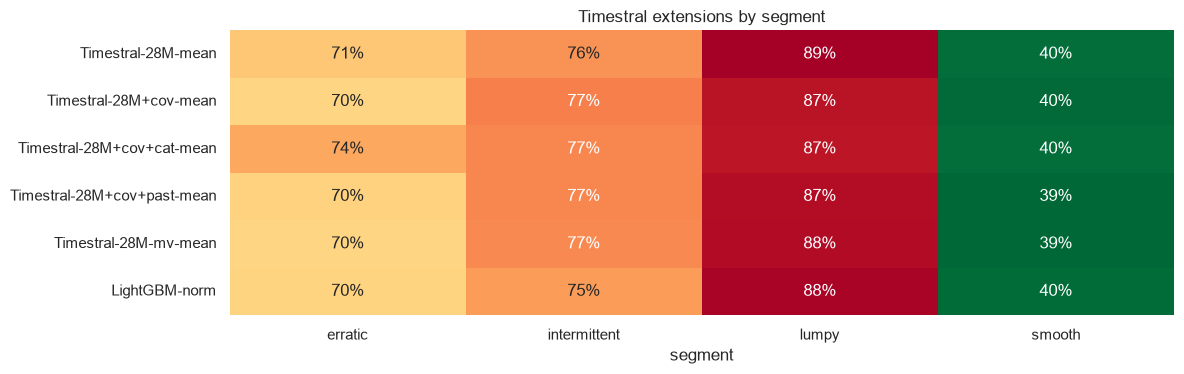

In [42]:
plot_heatmap(table=segment_scores_df.loc[ext], xlabel="segment", title="Timestral extensions by segment")
plt.tight_layout()
plt.show()

**Reading.**

* **Categorical events: no gain on the main origins.** 65.7% against 65.2% for the 0/1 event row (the
  bootstrap cannot tell them apart), with 24% more time. Their gain is on the holiday origins (section 9).
* **Past covariate (store total): no gain.** Same score as the known-covariate run (65.2%), slightly
  more bias, 25% more time. The store total mostly repeats the information already in the series' own
  history and calendar.
* **Multivariate: same accuracy, less than half the cost.** 65.4% against 65.2%, without item prices, in
  307 s instead of 722 s, because four series share one batch element. Joint forecasting of affine
  items does not uncover cross-series signal that the univariate model misses, but it is the cheapest
  way to add store-level covariates.
* None of the extensions changes the picture by segment.

## 8. Ensembles

Section 6 shows that the families win on different segments. An **equal-weight average** of models with
different strengths is the cheapest way to exploit that: there are no weights to fit, so it cannot overfit
the backtest. Ensembles help when the members' errors are not too correlated, which the first table checks
(correlation of the daily errors `F - A`).

In [43]:
members = sorted({member for ensemble in ENSEMBLES.values() for member in ensemble})
errors_df = merged_df[members].sub(other=merged_df["y"], axis=0)

errors_df.corr().style.format(formatter="{:.2f}").background_gradient(cmap="Blues")

,AutoARIMA,AutoETS,LightGBM-norm,Timestral-28M+cov-mean
AutoARIMA,1.00,0.90,0.89,0.92
AutoETS,0.90,1.00,0.88,0.88
LightGBM-norm,0.89,0.88,1.00,0.93
Timestral-28M+cov-mean,0.92,0.88,0.93,1.00


The ensembles next to their members, sorted by mean score per origin.

In [44]:
columns = ["wmape (overall)", "bias (overall)", "mean score per origin",
           f"FVA vs MA{settings.moving_average_window}"]
ensembles_df = results_df.loc[ENS + members, columns].sort_values(by="mean score per origin")

ensembles_df.style.format(formatter="{:.1%}").format(formatter="{:+.1%}", subset=["bias (overall)"])

,wmape (overall),bias (overall),mean score per origin,FVA vs MA28
model,,,,
"Ens(TS+cov, LGBM-norm, ETS)",62.4%,+0.7%,64.6%,5.8%
"Ens(TS+cov, LGBM-norm, ARIMA)",62.8%,+0.6%,64.9%,5.4%
"Ens(TS+cov, LGBM-norm)",62.9%,+1.6%,65.1%,5.1%
Timestral-28M+cov-mean,63.5%,+1.2%,65.2%,4.9%
LightGBM-norm,63.7%,+2.0%,66.3%,3.3%
AutoETS,63.5%,-1.2%,67.5%,1.6%
AutoARIMA,64.6%,-1.3%,67.6%,1.4%


**Reading.** The daily errors of the members are 88–93% correlated: they all miss the same spikes.
The ensembles still give the best score of the benchmark (64.6% with AutoETS, FVA +5.8%), but the gain
over Timestral-28M+cov alone is only 0.6 points. AutoETS is the best third member because its errors are
the least correlated with the others (0.88) and its negative bias offsets the positive bias of Timestral
and LightGBM. The equal-weight average has no parameter to tune, so this gain is not an artefact of the
backtest.

## 9. Holiday origins

The three main origins cover February–May 2016, a quiet period. Three more origins put the forecast
window across US holidays: **Independence Day** (origin 2015-06-21), **Thanksgiving** (2015-11-22) and
**Christmas and New Year** (2015-12-20), when stores close for a day and shopping patterns shift. Only the
models that matter for the conclusions are re-run (`settings.holiday_jobs`).

In [45]:
holiday_merged_df, h_timings = run_holiday_benchmark(settings, data)
holiday_merged_df = add_ensembles(df=holiday_merged_df)
H_MODELS = [model for model in MODELS if model in holiday_merged_df.columns and model not in TS]

holiday_scores_df = fold_table(df=holiday_merged_df, models=H_MODELS, metric="score")
holiday_overall_df = evaluate(df=holiday_merged_df, models=H_MODELS).set_index(keys="model")
holiday_compare_df = pd.concat(objs=[holiday_scores_df.rename(columns={"mean": "holidays mean"}),
                                     holiday_overall_df[["wmape", "bias"]].add_prefix(prefix="holidays "),
                                     scores_df.loc[H_MODELS, "mean"].rename(index="main origins mean")], axis=1)

(holiday_compare_df.sort_values(by="holidays mean").style.format(formatter="{:.1%}")
 .format(formatter="{:+.1%}", subset=["holidays bias"])
 .background_gradient(cmap="RdYlGn_r", subset=["holidays mean"]))

,2015-06-21,2015-11-22,2015-12-20,holidays mean,holidays wmape,holidays bias,main origins mean
model,,,,,,,
AutoETS,66.6%,78.4%,76.7%,73.9%,71.3%,+2.1%,67.5%
AutoCES,70.4%,73.6%,78.0%,74.0%,70.7%,-2.5%,71.6%
MA28,71.4%,75.5%,76.5%,74.5%,72.5%,-0.2%,68.6%
AutoARIMA,70.2%,80.3%,78.6%,76.4%,72.0%,+4.0%,67.6%
"Ens(TS+cov, LGBM-norm, ETS)",72.5%,84.2%,77.3%,78.0%,70.9%,+6.7%,64.6%
Timestral-28M+cov+cat-mean,72.1%,84.6%,78.5%,78.4%,71.1%,+6.9%,65.7%
"Ens(TS+cov, LGBM-norm, ARIMA)",73.7%,84.9%,78.1%,78.9%,71.2%,+7.4%,64.9%
"Ens(TS+cov, LGBM-norm)",76.3%,88.1%,78.6%,81.0%,71.7%,+9.0%,65.1%
Timestral-28M+cov-mean,74.8%,85.0%,83.8%,81.2%,71.6%,+9.2%,65.2%


Total daily units of the Christmas / New Year window, actual against five forecasts: the forecasts
repeat the usual weekly shape, while the actuals spike before the holidays and drop to zero on
Christmas Day.

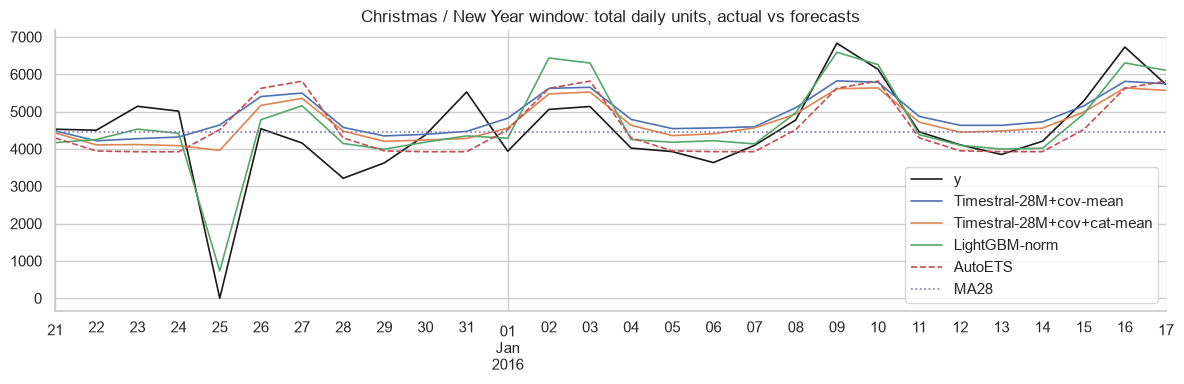

In [46]:
xmas_df = holiday_merged_df[holiday_merged_df["cutoff"] == holiday_cutoffs[-1]]
shown = ["y", "Timestral-28M+cov-mean", "Timestral-28M+cov+cat-mean", "LightGBM-norm", "AutoETS", f"MA{settings.moving_average_window}"]
xmas_daily_df = xmas_df.groupby(by="ds")[shown].sum()

ax = xmas_daily_df.plot(figsize=(FIG_WIDTH, 4), lw=1.2, style=["k-", "-", "-", "-", "--", ":"])
ax.set_xlabel("")
ax.set_title("Christmas / New Year window: total daily units, actual vs forecasts")
plt.tight_layout()
plt.show()

Christmas Day alone: total units of the three stores, actual against every forecast.

In [47]:
christmas_df = (xmas_df[xmas_df["ds"] == pd.Timestamp("2015-12-25")][["y", *H_MODELS]].sum()
                .to_frame(name="units on 25 December").sort_values(by="units on 25 December"))

christmas_df.style.format(formatter="{:,.0f}")

,units on 25 December
y,2
LightGBM-norm-matched+cat,58
LightGBM-norm-matched,333
LightGBM-norm,732
"Ens(TS+cov, LGBM-norm)","2,687"
"Ens(TS+cov, LGBM-norm, ETS)","3,296"
"Ens(TS+cov, LGBM-norm, ARIMA)","3,317"
Timestral-28M+cov+cat-mean,"3,962"
SeasonalNaive,"4,345"
AutoCES,"4,388"


The paired bootstrap of section 6 on the holiday origins, again against Timestral-28M+cov (mean).

In [48]:
bootstrap_table(df=holiday_merged_df)

,difference,lower,upper,share better
AutoETS,-7.1%,-8.9%,-4.7%,100%
MA28,-6.7%,-9.3%,-3.2%,100%
AutoARIMA,-4.9%,-6.5%,-3.1%,100%
"Ens(TS+cov, LGBM-norm, ETS)",-3.2%,-4.1%,-2.3%,100%
Timestral-28M+cov+cat-mean,-2.8%,-3.3%,-2.3%,100%
LightGBM-norm-matched+cat,+0.2%,-2.0%,+2.6%,42%
LightGBM-norm,+0.7%,-0.8%,+2.5%,18%
LightGBM-norm-matched,+1.0%,-1.4%,+3.4%,21%
Timestral-28M-mean,+1.5%,+0.8%,+2.0%,0%


**Reading. The ranking does not survive the holidays.**

* **The simple models win**: AutoETS 73.9%, AutoCES 74.0%, moving average 74.5%. The best ensemble scores
  78.0%, Timestral-28M+cov+cat 78.4%, Timestral-28M+cov 81.2%, the LightGBM variants 81.5–82.2%. The
  bootstrap puts AutoETS 7.1 points ahead of Timestral-28M+cov (4.7–8.9), in every resample.
* **Categorical events are the one extension that pays off here**: 2.8 points better than the 0/1 row
  (2.3–3.3, in every resample), almost all of it at the Christmas origin (78.5% against 83.8%), and the
  bias drops from +9.2% to +6.9%.
* **Accuracy is not the problem, bias is.** The holiday WMAPE is almost the same for every serious model
  (70.7–72.8%; the ensemble has the best, 70.9%). Timestral and LightGBM over-forecast by 7–10%,
  AutoETS by 2% and the moving average not at all.
* **Where the bias comes from.** Timestral and LightGBM project the usual weekend peaks, but the weekends
  around Thanksgiving, Christmas and Independence Day sold less than usual. The pre-holiday peaks
  (25 November, 23–24 and 31 December, 3 July) are missed by every model.
* **Christmas Day.** Stores are closed (2 units sold in total). With the 0/1 row Timestral+cov forecasts
  about 4,640 units, as many as the models with no event information. With the categorical events it reads
  the closure (Christmas is encoded at a third of an ordinary day, section 3) but follows it only partly:
  3,962 units. The trees use the category as a split: LightGBM-norm-matched+cat forecasts 58 units,
  LightGBM-norm 732.
* The result holds without Christmas Day and at the weekly level.

Categorical events reduce the holiday problem but do not solve it: holiday windows still need a bias
correction or a holiday-aware model.

## 10. Evaluation at the level of the decision

A replenishment order rarely covers a single day: it covers a week, or the supplier lead time. What the
planner experiences is the error on the **sum** of the forecasts over that period, where daily errors of
opposite sign partly cancel. Here every series is aggregated into weekly buckets and into the full 28-day
window before computing the same score.

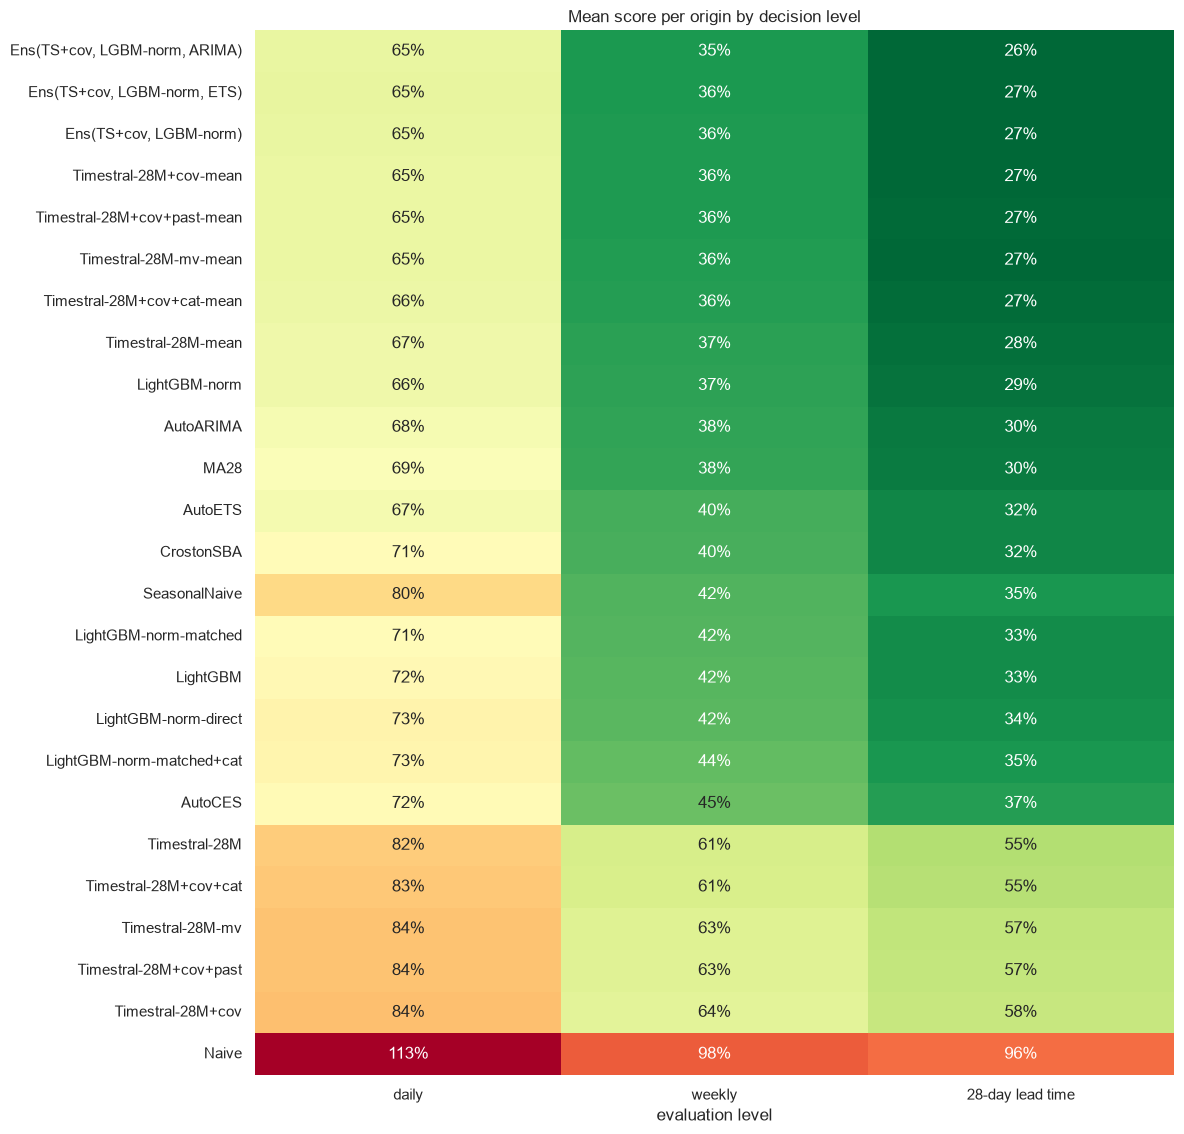

In [49]:
decision_levels = {"daily": 1, "weekly": 7, "28-day lead time": settings.horizon}
level_scores = {}
for name, days in decision_levels.items():
    agg_df = merged_df if days == 1 else aggregate_periods(df=merged_df, models=MODELS, days=days)
    level_scores[name] = fold_table(df=agg_df, models=MODELS, metric="score")["mean"]
decision_df = pd.DataFrame(data=level_scores).sort_values(by="weekly")

plot_heatmap(table=decision_df, xlabel="evaluation level",
             title="Mean score per origin by decision level")
plt.tight_layout()
plt.show()

Rank of the five best models at each level (1 = best): the top of the ranking does not change.

In [50]:
decision_df.rank().astype(int).head()

,daily,weekly,28-day lead time
model,,,
"Ens(TS+cov, LGBM-norm, ARIMA)",2,1,1
"Ens(TS+cov, LGBM-norm, ETS)",1,2,2
"Ens(TS+cov, LGBM-norm)",3,3,3
Timestral-28M+cov-mean,4,4,4
Timestral-28M+cov+past-mean,5,5,6


The paired bootstrap at the weekly level: every series and origin aggregated into four weekly buckets.

In [51]:
bootstrap_table(df=aggregate_periods(df=merged_df, models=KEY_MODELS, days=7))

,difference,lower,upper,share better
"Ens(TS+cov, LGBM-norm, ETS)",-0.4%,-1.3%,+0.3%,83%
Timestral-28M+cov+cat-mean,+0.4%,-0.9%,+1.2%,28%
Timestral-28M-mean,+1.2%,+0.2%,+1.8%,1%
LightGBM-norm,+1.4%,+0.0%,+2.3%,2%
AutoARIMA,+1.8%,+0.3%,+3.2%,1%
MA28,+2.0%,+0.0%,+3.8%,2%
AutoETS,+3.9%,+1.7%,+5.7%,0%
LightGBM-norm-matched,+5.7%,+3.1%,+10.4%,0%
LightGBM-norm-matched+cat,+7.4%,+3.2%,+15.4%,0%


**Reading.**

* **Aggregation compresses the errors** (from about 65% daily to 35–38% weekly and 26–30% on the 28-day
  total) **but keeps the ranking at the top**: the ensembles and Timestral-28M+cov stay first at every
  level.
* **The gaps widen in relative terms.** On the 28-day total per series the ensemble with AutoARIMA scores
  26.4% and Timestral-28M+cov 26.7%, against 28.5% for LightGBM-norm, 29.5% for AutoARIMA and 30.0% for
  the moving average.
* **At the weekly level the lead over LightGBM-norm becomes clearer**: 1.4 points, an interval that just excludes zero (up to 2.4), with
  LightGBM ahead in 2% of the resamples, while the ensemble is no longer distinguishable from Timestral
  alone (−0.4, −1.3 to +0.3).
* **AutoETS drops** below the moving average at the weekly level (40.0% vs 38.1%), although it beats it
  on the daily score: its daily errors do not cancel within the week.

The right evaluation level depends on the replenishment process, and it can change which benchmark is a
fair comparison.

## 11. Stock decisions from the quantiles

Sections 6–10 reduce every forecast to a point. A replenishment decision needs a quantity: the
**order-up-to level** S that covers the demand of a period with a target probability, the **cycle service
level**. Timestral gives it directly, as a quantile; a point forecast needs a safety stock on top. For
every series, origin and period (each of the four weeks, or the whole 28-day window):

* **Timestral quantiles.** S is the quantile of the period demand at the target level. Timestral forecasts
  the distribution of each day, not of their sum, so the period quantile needs an assumption on how the
  days are linked. Two bounds: **comonotonic** (days perfectly correlated: the sum of the daily
  quantiles, the widest spread) and **independent** (the distribution of the sum is simulated from the
  daily quantiles, the narrowest spread). In between, **correlated**: the days are drawn through a
  one-factor Gaussian copula in which every pair of days has correlation ρ (ρ = 0 is independent, ρ = 1
  comonotonic), and ρ is fitted on the backtest.
* **Point forecast + normal safety stock**, the classic planner rule: S = period forecast + z · σ · √days,
  with σ the standard deviation of daily demand over the 56 days before the origin. Applied to Timestral's
  mean, LightGBM-norm and the moving average.

S is rounded up to whole units. Three metrics per target level: the **cycle service** achieved (share of
periods with demand within S; it should match the target), the **fill rate** (share of the units
demanded that are served from stock) and the **leftover per unit sold** (stock left at the end of the
period over demand, the cost side).

### Fitting the correlation between days

For each candidate ρ the **calibration error** is the mean gap between the cycle service achieved and
the target, over the four targets, with the three origins pooled. Every candidate is a full simulation,
so this cell takes a few minutes.

In [52]:
STOCK_ALIAS = "Timestral-28M+cov"
PERIODS = {"weekly": 7, "28-day": settings.horizon}

sweeps = {name: correlation_sweep(df=merged_df, alias=STOCK_ALIAS, days=days)
          for name, days in PERIODS.items()}
calibration_df = pd.DataFrame(data={name: calibration_error(levels_df=sweep, by=["correlation"])
                                    for name, sweep in sweeps.items()})

(calibration_df.style.format(formatter="{:.1%}").format_index(formatter="{:.2f}")
 .background_gradient(cmap="RdYlGn_r"))

,weekly,28-day
correlation,,
0.00,2.1%,9.1%
0.05,1.5%,3.5%
0.10,1.7%,1.4%
0.15,2.1%,1.7%
0.20,2.5%,2.3%
0.30,3.2%,3.4%
0.50,4.3%,4.5%
1.00,5.0%,4.1%


To score every origin with a ρ fitted without it, ρ is chosen **leave-one-origin-out**: for each origin,
the ρ with the smallest calibration error on the other two. These are the values used by the
`(fitted correlation)` policy below.

In [53]:
fits = {name: cross_validate_correlation(sweep_df=sweep) for name, sweep in sweeps.items()}
fitted_correlation_df = pd.DataFrame(data={name: chosen for name, (_, chosen) in fits.items()})

fitted_correlation_df.rename_axis(mapper="held-out origin")

,weekly,28-day
held-out origin,,
2016-02-28,0.05,0.10
2016-03-27,0.10,0.15
2016-04-24,0.05,0.10


Every policy on weekly periods:

In [54]:
STOCK_POINT = [f"{STOCK_ALIAS}-mean", "LightGBM-norm", f"MA{settings.moving_average_window}"]


def stock_policies(name: str) -> pd.DataFrame:
    days = PERIODS[name]
    frames = [quantile_order_up_to(df=merged_df, alias=STOCK_ALIAS, days=days, method=method)
              for method in ("comonotonic", "independent")]
    frames.append(fits[name][0])
    frames += [normal_order_up_to(df=merged_df, model=model, y_df=y_df, days=days)
               for model in STOCK_POINT]
    return service_metrics(levels_df=pd.concat(objs=frames))


weekly_stock_df = stock_policies(name="weekly")

(weekly_stock_df.unstack(level="service_level").style.format(formatter="{:.0%}")
 .format_index(formatter="{:.0%}", axis=1, level=1))

The same for the 28-day window, one order covering the whole horizon:

In [55]:
window_stock_df = stock_policies(name="28-day")

(window_stock_df.unstack(level="service_level").style.format(formatter="{:.0%}")
 .format_index(formatter="{:.0%}", axis=1, level=1))

The trade-off between service and stock: fill rate against leftover per unit sold, one point per target
level (80%, 90%, 95%, 98%). A curve higher and to the left serves more with less stock. The comonotonic
policy is left out: it needs 0.5 to 2.7 units of leftover per unit sold.

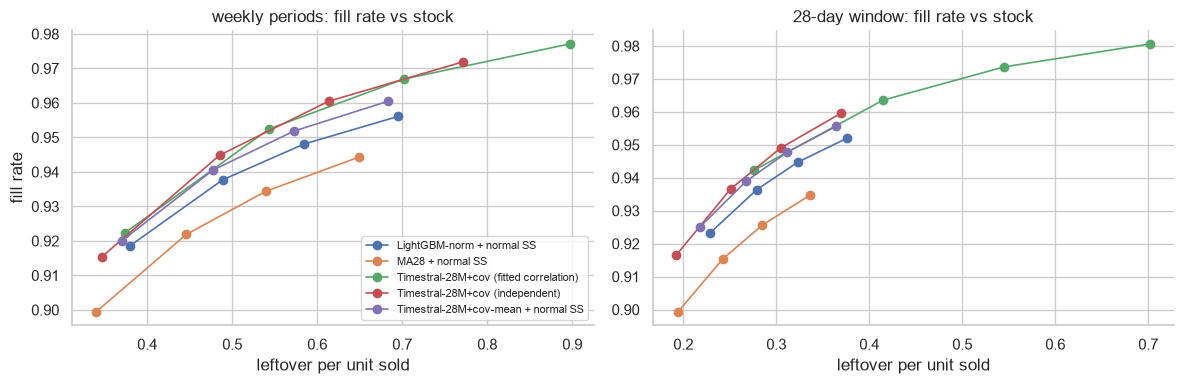

In [56]:
stock_tables = {"weekly periods": weekly_stock_df, "28-day window": window_stock_df}
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(FIG_WIDTH, 4))

for ax, (name, table) in zip(axes, stock_tables.items(), strict=True):
    for policy, part in table.drop(index=f"{STOCK_ALIAS} (comonotonic)", level="policy").groupby(level="policy"):
        ax.plot(part["leftover per unit sold"], part["fill rate"], marker="o", lw=1.2, label=policy)
    ax.set_xlabel("leftover per unit sold")
    ax.set_title(f"{name}: fill rate vs stock")
axes[0].set_ylabel("fill rate")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading.**

* **The days are weakly but not negligibly correlated.** The calibration error is smallest at ρ ≈ 0.05
  for weekly periods and ρ ≈ 0.10 for the 28-day window, and leaving out any one origin moves the choice
  by one step of the grid at most (0.05–0.15). Over a week independence is nearly right (2.1% error);
  over four weeks it is not (9.1%), because a small correlation adds up over 28 days.
* **With ρ fitted, the target means what it says.** On held-out origins the fitted policy reaches 83%,
  91%, 94% and 96% of cycle service for weekly targets of 80–98%, and 82%, 90%, 94% and 96% on the 28-day
  window, where independent days gave 73–89% and the normal rule 69–89%. Only the 98% target stays about
  two points short, at the edge of what quantiles truncated at q99 can express.
* **Calibration moves the policy along its curve, it does not improve the curve.** At the same leftover
  stock, the Timestral policies and the normal rule on Timestral's mean or on LightGBM-norm serve about
  the same share of demand (within a point), the moving average one to two points less. What the fitted
  quantiles add is a service level that can be set directly: the normal rule needs its targets
  over-stated by several points, by an amount that differs between a week and a lead time of four weeks.
* **The normal rule misses the high targets**: 98% gives 91–94% of cycle service on weekly periods and
  84–89% on the 28-day window, because demand on intermittent items has a heavier right tail than a
  normal distribution.

## 12. Limits and problems of Timestral found in this analysis

The headline result is positive, but the path to it ran into several issues that anyone using Timestral on
retail demand should know about. The cell below quantifies the most serious one, the constant-price
problem, on the last origin.

In [57]:
_, n_flat = mask_constant_covariate(inputs=inputs, name="sell_price", window=settings.timestral_max_context)

print(f"Last origin: {n_flat:,} of {len(inputs.unique_ids):,} series ({n_flat / len(inputs.unique_ids):.0%}) have a flat price in the context and get it masked")

Last origin: 1,022 of 2,469 series (41%) have a flat price in the context and get it masked


With the mask, the largest mean forecast of each Timestral run stays below 90 units at every origin:
no blow-ups.

In [58]:
cols = ["Timestral-28M-mean", "Timestral-28M+cov-mean", "Timestral-28M+cov+cat-mean",
        "Timestral-28M+cov+past-mean", "Timestral-28M-mv-mean"]

merged_df.groupby(by="cutoff")[cols].max().round(decimals=0).rename(columns=lambda column: f"max {column}")

,max Timestral-28M-mean,max Timestral-28M+cov-mean,max Timestral-28M+cov+cat-mean,max Timestral-28M+cov+past-mean,max Timestral-28M-mv-mean
cutoff,,,,,
2016-02-28,68.0,69.0,78.0,67.0,73.0
2016-03-27,84.0,79.0,82.0,79.0,81.0
2016-04-24,82.0,83.0,89.0,87.0,82.0


1. **The default point forecast is biased.** The median under-forecasts intermittent demand by about
   24%. The mean has to be approximated from 21 quantiles: the tails beyond q01 and q99 are truncated, and
   the result depends on the quantile grid.
2. **Covariates are fragile.** Timestral normalises every covariate row by its variability over the
   context. A price that never moved (41% of the series here) and then changes in the horizon becomes an
   extreme input and blows up the upper quantiles. The fix (masking flat prices as missing) works for the
   28M; the 209M stayed unstable and is left out of the analysis. Reported as
   [mistralai/timestral#7](https://github.com/mistralai/timestral/issues/7).
3. **`symmetric_averaging` negates the covariates.** The mirrored pass feeds the model negative prices,
   which are outside its training distribution. With the mask it does no harm, but the interaction is not
   documented.
4. **Covariates are expensive.** On CPU they multiply the inference time by about 20 (722 s against 35 s
   for three origins) for a 1.3-point gain.
5. **Events are read, but only partly followed.** As categorical covariates, event name and type let
   Timestral tell a store closure from a sporting event (Christmas is encoded at a third of an ordinary
   day) and improve the holiday score by 2.8 points, yet on Christmas Day it still forecasts about 4,000
   units for closed stores, and on holiday windows it over-forecasts by about 7%.
6. **Multivariate forecasting needs shared covariates**, so item prices cannot be used, and it brought
   no accuracy gain.
7. **Possible training-data overlap.** M5 is public and widely used; we could not verify whether it is
   part of Timestral's pre-training corpus, which would flatter the zero-shot results.
8. **Small sample of origins.** Three main and three holiday windows; the bootstrap intervals cover the
   choice of items, not of origins, and differences of about one point between models are within the
   origin-to-origin variation.
9. **Daily quantiles only.** Timestral forecasts the distribution of each day, not of a period's total.
   For a stock decision the period quantile has to be assembled with a dependence between days that the
   model does not provide; here a single correlation fitted on three origins (ρ ≈ 0.05–0.15) is enough,
   but it is a property of this data and has to be re-fitted elsewhere.

## 13. Conclusions

* **Zero-shot, Timestral-28M with known covariates is the best single model** on the main origins
  (score 65.2%, FVA +4.9% over the moving average), ahead of a tuned LightGBM and of AutoARIMA / AutoETS,
  provided the **mean of the quantiles** is used as the point forecast and flat prices are masked. The
  lead over LightGBM-norm (1 point) is likely but not certain on the series bootstrap.
* **On the same information** as Timestral, LightGBM falls five points behind it: the tuned LightGBM
  owes its place to features (ids, day / month / year, price ratio, full history) that Timestral
  does not use.
* **An equal-weight ensemble** of Timestral, LightGBM-norm and AutoETS adds 0.6 points: small, because the
  members make the same mistakes.
* **At the level of the decision** (weekly or 28-day totals) the advantage holds and widens in relative
  terms.
* **On holiday windows the advantage disappears**: simple exponential smoothing wins. Categorical events
  close about a third of the gap (78.4% against 81.2%, AutoETS 73.9%) but Timestral still over-forecasts
  by about 7%. This is the main caveat before using it for replenishment.
* **For stock decisions** the daily quantiles, combined with a small correlation between days fitted
  on the backtest (ρ ≈ 0.1), hit the target service on held-out origins both weekly and over 28 days,
  which a point forecast with a normal safety stock does not. The service / stock trade-off itself is
  about the same as with the normal rule on a good point forecast.
* **Past covariates and multivariate grouping** do not improve accuracy; the multivariate run is a cheap
  way to add store-level information.

**Next steps**

* **Correct the holiday bias**: Timestral reads the closure in its event encoding but follows it only
  partly; a post-hoc correction per event, fitted on past holidays, is the cheapest test.
* **Extend the backtest** to a full year of origins, then more departments and stores: the bootstrap
  covers the items, not the origins.